# Fairness audit of a loan model
**Veritas AI · International High School Hackathon 2026 · Project 4.2.3**

*This project is a prototype and is not financial advice.*

**Goal:** build a model that decides who gets a loan, then test whether it treats young applicants (under 25) differently from everyone else, and work out why.

| Section | What it does |
|---|---|
| 0 | Setup |
| 1 | Data (with corrected category labels), the 5:1 cost rule, three models against two baselines, the full scorecard, and how we pick a model |
| 2 | Fairness: approval rates for under-25s vs 25+, the gap, how sure we are, and age bands with counts |
| 3 | What drives the gap, what each model relies on (weightings), and one applicant step by step |
| 4 | Proxy test: does deleting age remove the bias? |
| 5 | Fixing the gap, what it costs, and which fix a UK lender could actually use |
| 6 | Flip test, an audit of the data itself, and deeper fairness checks |
| 7 | Tail risk: losses by loan size, recessions and worst cases |
| 8 | Interactive demo |
| 9 | Limitations, and what this data can and can't measure |
| 10 | Straight answers to the six big questions |

**How to read it.** Every analysis answers one question, written in **bold** before the table or chart. The result is printed underneath, straight from the numbers. Where a paragraph quotes a number, it was checked against that printed output.

**Conventions.** `y = 1` means the applicant **repaid** (a good risk). `p` is the model's chance that they repay. The bank lends when `p` is above the cut-off. Every result comes from applicants the model never saw while it was being trained (out of fold), with fixed random seeds, so **Run all** gives the same numbers every time.

*How to use this notebook in Colab: **Runtime → Run all**. Everything downloads automatically.*

## 0. Setup

In [1]:
!pip install -q ucimlrepo fairlearn

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, average_precision_score, brier_score_loss
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

SEED = 42                      # fixed so everyone gets the same numbers
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 3)

# Chart colours (colour-blind safe pair)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
MODEL_COLOURS = {"Logistic regression": BLUE, "Random forest": ORANGE, "Gradient boosting": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

## 1. Data and models

### 1.1 Load the data
The Statlog German Credit dataset: 1,000 loans from a bank in southern Germany, 1973–75, 20 details each, labelled **good risk** (the loan was repaid as agreed) or **bad risk** (it wasn't).

**We corrected the category labels.** The UCI version stores categories as codes like `A11`, and its codebook translates many of them wrongly. Grömping (2019) went back to the original German documents and published a corrected version, **South German Credit**, on the same UCI repository. Section 1.1b matches our rows to it and shows the evidence. Three examples:

| Code | Old Statlog label | What it really means |
|---|---|---|
| `A14` (checking account) | no checking account | 200 DM or more, or a salary account |
| `A151` (housing) | rent | lives for free |
| `A121` (property) | real estate | no property |

**This changes the names only, not a single number.** The same people stay in the same groups, so every model, gap and interval is identical. What changes is what we can honestly *say* about them.

Four details look like numbers but are really ordered categories coded 1 to 4: installment rate, years at current address, number of credits at this bank, and number of people supported. The model keeps them as 1 to 4, but explanations show what they mean. **Installment rate is a puzzle:** the Statlog codebook says code 4 is the *heaviest* repayment burden, the corrected codebook says it's the *lightest* (under 20% of income), and in our data code 4 has the *lowest* repayment rate, which fits the Statlog reading better. We can't settle which is right, so we show it as "band 1 to 4" and don't interpret its direction.

In [3]:
COLS = ["status", "duration", "credit_history", "purpose", "amount", "savings",
        "employment_duration", "installment_rate", "personal_status_sex", "other_debtors",
        "present_residence", "property", "age", "other_installment_plans", "housing",
        "number_credits", "job", "people_liable", "telephone", "foreign_worker"]

# Translation of UCI codes, CORRECTED using South German Credit (Groemping 2019); section 1.1b shows the evidence
CODES = {
 "A11": "no checking account", "A12": "< 0 DM (overdrawn)", "A13": "0-200 DM", "A14": ">= 200 DM or salary account",
 "A30": "past payment delays", "A31": "critical account / credits elsewhere", "A32": "no credits or all paid back duly",
 "A33": "existing credits paid duly so far", "A34": "all credits at this bank paid duly",
 "A40": "other", "A41": "car (new)", "A42": "car (used)", "A43": "furniture", "A44": "radio/TV",
 "A45": "appliances", "A46": "repairs", "A47": "education", "A48": "vacation", "A49": "retraining", "A410": "business",
 "A61": "unknown / no savings account", "A62": "< 100 DM", "A63": "100-500 DM", "A64": "500-1000 DM", "A65": ">= 1000 DM",
 "A71": "unemployed", "A72": "< 1 year", "A73": "1-4 years", "A74": "4-7 years", "A75": ">= 7 years",
 # Sex can't be fully recovered: code A92 mixes women who are not single with single men
 "A91": "male: divorced/separated", "A92": "female (not single) or male (single)",
 "A93": "male: married/widowed", "A94": "female: single", "A95": "unused code",
 "A101": "none", "A102": "co-applicant", "A103": "guarantor",
 "A121": "no property / unknown", "A122": "car or other", "A123": "building society savings / life insurance", "A124": "real estate",
 "A141": "bank", "A142": "stores", "A143": "none",
 "A151": "lives for free", "A152": "rents", "A153": "owns home",
 "A171": "unemployed / unskilled non-resident", "A172": "unskilled resident",
 "A173": "skilled", "A174": "management / self-employed",
 "A191": "no", "A192": "yes (own name)", "A201": "no", "A202": "yes",
}
# Details stored as numbers 1-4 that are really ordered categories (meanings from the corrected codebook)
ORDINAL = {"installment_rate": {1: "band 1 of 4", 2: "band 2 of 4", 3: "band 3 of 4", 4: "band 4 of 4"},   # meaning disputed, see 6.2
           "present_residence": {1: "< 1 year", 2: "1-4 years", 3: "4-7 years", 4: ">= 7 years"},
           "number_credits": {1: "1", 2: "2-3", 3: "4-5", 4: "6 or more"},
           "people_liable": {1: "0 to 2", 2: "3 or more"}}
def show_value(f, v):
    """How to display one detail's value in plain English."""
    return f"{v} ({ORDINAL[f][int(v)]})" if f in ORDINAL else str(v)

BACKUP_URL = "https://raw.githubusercontent.com/selva86/datasets/master/GermanCredit.csv"
# The backup copy uses its own category wording, so we convert it back to the official UCI codes.
# Fallback only: if it is ever used, re-check the labels against section 1.1b.
BACKUP_TO_UCI = {"status": {"... < 100 DM": "A11", "... >= 200 DM / salary for at least 1 year": "A13", "0 <= ... < 200 DM": "A12", "no checking account": "A14"}, "credit_history": {"all credits at this bank paid back duly": "A31", "critical account/other credits existing": "A34", "delay in paying off in the past": "A33", "existing credits paid back duly till now": "A32", "no credits taken/all credits paid back duly": "A30"}, "purpose": {"business": "A48", "car (new)": "A40", "car (used)": "A41", "domestic appliances": "A43", "education": "A45", "furniture/equipment": "A410", "others": "A49", "radio/television": "A42", "repairs": "A44", "retraining": "A46"}, "savings": {"... < 100 DM": "A61", "... >= 1000 DM": "A64", "100 <= ... < 500 DM": "A62", "500 <= ... < 1000 DM": "A63", "unknown/no savings account": "A65"}, "employment_duration": {"... < 1 year": "A72", "... >= 7 years": "A75", "1 <= ... < 4 years": "A73", "4 <= ... < 7 years": "A74", "unemployed": "A71"}, "personal_status_sex": {"female : divorced/separated/married": "A92", "male : divorced/separated": "A91", "male : married/widowed": "A94", "male : single": "A93"}, "other_debtors": {"co-applicant": "A102", "guarantor": "A103", "none": "A101"}, "property": {"building society savings agreement/life insurance": "A122", "car or other": "A123", "real estate": "A121", "unknown/no property": "A124"}, "other_installment_plans": {"bank": "A141", "none": "A143", "stores": "A142"}, "housing": {"for free": "A153", "own": "A152", "rent": "A151"}, "job": {"management/self-employed/highly qualified employee/officer": "A174", "skilled employee/official": "A173", "unemployed/unskilled - non-resident": "A171", "unskilled - resident": "A172"}, "telephone": {"no": "A191", "yes": "A192"}, "foreign_worker": {"no": "A202", "yes": "A201"}}

def from_uci_codes(X, target):
    """Official UCI format (codes like A11, target 1 = good, 2 = bad) -> readable table."""
    X = X.copy()
    X.columns = COLS
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype(str).map(lambda v: CODES.get(v, v))
    y = (pd.Series(target).astype(int).to_numpy() == 1).astype(int)
    return X.reset_index(drop=True), pd.Series(y, name="good")

def load_data():
    """1) UCI via ucimlrepo, as the brief asks  2) a local german.data file  3) a GitHub backup copy."""
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=144)
        X = d.data.features
        if all(str(c).startswith("Attribute") for c in X.columns):   # make sure Attribute1..20 are in order
            X = X[sorted(X.columns, key=lambda c: int(str(c).replace("Attribute", "")))]
        return (*from_uci_codes(X, d.data.targets.iloc[:, 0]), "UCI, fetch_ucirepo(id=144)")
    except Exception as e:
        print("UCI download failed:", e)
    import os
    if os.path.exists("german.data"):
        raw = pd.read_csv("german.data", sep=" ", header=None)
        return (*from_uci_codes(raw.iloc[:, :20], raw.iloc[:, 20]), "local german.data file")
    raw = pd.read_csv(BACKUP_URL)
    target = raw.pop("credit_risk").map({1: 1, 0: 2})                   # backup: 1 = good, 0 = bad
    X = raw[COLS].copy()
    for c, mapping in BACKUP_TO_UCI.items():
        X[c] = X[c].map(mapping)
    return (*from_uci_codes(X, target), "GitHub backup copy (converted to UCI codes)")

X, y, SOURCE = load_data()
young = (X["age"] < 25).to_numpy()            # the group we audit

print(f"Source: {SOURCE}")
print(f"{len(X):,} applicants, {X.shape[1]} details each")
print(f"Good risks: {y.sum()}   Bad risks: {(1 - y).sum()}")
print(f"Under 25: {young.sum()}   25 or older: {(~young).sum()}")
X.head()

Source: UCI, fetch_ucirepo(id=144)
1,000 applicants, 20 details each
Good risks: 700   Bad risks: 300
Under 25: 149   25 or older: 851


,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,present_residence,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker
0,no checking account,6,all credits at this bank paid duly,furniture,1169,>= 1000 DM,>= 7 years,4,male: married/widowed,none,4,no property / unknown,67,none,rents,2,skilled,1,yes (own name),no
1,< 0 DM (overdrawn),48,no credits or all paid back duly,furniture,5951,unknown / no savings account,1-4 years,2,female (not single) or male (single),none,2,no property / unknown,22,none,rents,1,skilled,1,no,no
2,>= 200 DM or salary account,12,all credits at this bank paid duly,repairs,2096,unknown / no savings account,4-7 years,2,male: married/widowed,none,3,no property / unknown,49,none,rents,1,unskilled resident,2,no,no
3,no checking account,42,no credits or all paid back duly,car (used),7882,unknown / no savings account,4-7 years,2,male: married/widowed,guarantor,4,car or other,45,none,owns home,1,skilled,2,no,no
4,no checking account,24,existing credits paid duly so far,other,4870,unknown / no savings account,1-4 years,3,male: married/widowed,none,4,real estate,53,none,owns home,2,skilled,2,no,no


### 1.1b Checking the labels against the corrected dataset
**Question:** are the corrected labels right for *our* rows, or just for someone else's copy?

We download South German Credit from UCI and match each of our applicants to it on loan length, amount, age and outcome. Then, for each detail, we check which corrected category our code lines up with.

In [4]:
import io, zipfile, urllib.request
SGC_LABELS = {
    "status": {1: "no checking account", 2: "< 0 DM", 3: "0-200 DM", 4: ">= 200 DM / salary for at least 1 year"},
    "credit_history": {0: "delay in paying off in the past", 1: "critical account/other credits elsewhere",
                       2: "no credits taken/all credits paid back duly", 3: "existing credits paid back duly till now",
                       4: "all credits at this bank paid back duly"},
    "savings": {1: "unknown/no savings account", 2: "< 100 DM", 3: "100-500 DM", 4: "500-1000 DM", 5: ">= 1000 DM"},
    "personal_status_sex": {1: "male : divorced/separated", 2: "female : non-single or male : single",
                            3: "male : married/widowed", 4: "female : single"},
    "property": {1: "unknown / no property", 2: "car or other", 3: "building soc. savings agr./life insurance", 4: "real estate"},
    "housing": {1: "for free", 2: "rent", 3: "own"},
    "foreign_worker": {1: "yes", 2: "no"},
    "installment_rate": {1: ">= 35", 2: "25 <= ... < 35", 3: "20 <= ... < 25", 4: "< 20"},
    "people_liable": {1: "3 or more", 2: "0 to 2"},
}
try:
    url = "https://archive.ics.uci.edu/static/public/573/south+german+credit+update.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=30).read()))
    sgc = pd.read_csv(z.open("SouthGermanCredit.asc"), sep=r"\s+")
    sgc.columns = COLS + ["good"]
    key = ["duration", "amount", "age", "good"]
    matched = X.assign(good=y.to_numpy()).merge(sgc, on=key, suffixes=("", "_sgc"))
    print(f"{len(matched)} of {len(X)} applicants match exactly on loan length, amount, age and outcome "
          f"(the other {len(X) - len(matched)} are records Grömping corrected).\n")
    check_rows = []
    for c, labels in SGC_LABELS.items():
        ct = pd.crosstab(matched[c], matched[c + "_sgc"])
        for ours, r in ct.iterrows():
            check_rows.append({"detail": c.replace("_", " "), "label we use": show_value(c, ours),
                               "corrected codebook": labels[r.idxmax()], "rows that agree": f"{r.max()} of {r.sum()}"})
    display(pd.DataFrame(check_rows).set_index(["detail", "label we use"]))
except Exception as e:
    print("Could not download South German Credit to re-check the labels:", e)

990 of 1000 applicants match exactly on loan length, amount, age and outcome (the other 10 are records Grömping corrected).



corrected codebook  \
detail              label we use                                                                             
status              0-200 DM                                                                      0-200 DM   
                    < 0 DM (overdrawn)                                                              < 0 DM   
                    >= 200 DM or salary account                     >= 200 DM / salary for at least 1 year   
                    no checking account                                                no checking account   
credit history      all credits at this bank paid duly             all credits at this bank paid back duly   
                    critical account / credits elsewhere          critical account/other credits elsewhere   
                    existing credits paid duly so far             existing credits paid back duly till now   
                    no credits or all paid back duly           no credits taken/all credits paid back duly   
                    past payment delays                                    delay in paying off in the past   
savings             100-500 DM                                                                  100-500 DM   
                    500-1000 DM                                                                500-1000 DM   
                    < 100 DM                                                                      < 100 DM   
                    >= 1000 DM                                                                  >= 1000 DM   
                    unknown / no savings account                                unknown/no savings account   
personal status sex female (not single) or male (single)              female : non-single or male : single   
                    female: single                                                         female : single   
                    male: divorced/separated                                     male : divorced/separated   
                    male: married/widowed                                           male : married/widowed   
property            building society savings / life insurance    building soc. savings agr./life insurance   
                    car or other                                                              car or other   
                    no property / unknown                                            unknown / no property   
                    real estate                                                                real estate   
housing             lives for free                                                                for free   
                    owns home                                                                          own   
                    rents                                                                             rent   
foreign worker      no                                                                                  no   
                    yes                                                                                yes   
installment rate    1 (band 1 of 4)                                                                  >= 35   
                    2 (band 2 of 4)                                                         25 <= ... < 35   
                    3 (band 3 of 4)                                                         20 <= ... < 25   
                    4 (band 4 of 4)                                                                   < 20   
people liable       1 (0 to 2)                                                                      0 to 2   
                    2 (3 or more)                                                                3 or more   

                                                              rows that agree  
detail              label we use                                               
status              0-200 DM                                         62 of 62

**What this shows:** for every detail checked, each of our codes lines up with exactly one corrected category in (nearly) every matched row. So the corrected labels describe our data, and the old Statlog wording was wrong for these details. The few rows that disagree are among the records Grömping corrected.

**First look. Question:** how often did people in each age group actually repay? This matters later, because if young people really did repay less often, some gap in approvals may be expected. The question is whether the model's gap is *bigger* than the real difference.

In [5]:
first_look = pd.DataFrame({
    "applicants": [young.sum(), (~young).sum()],
    "repaid (good)": [int(y[young].sum()), int(y[~young].sum())],
    "did not repay (bad)": [int((1 - y[young]).sum()), int((1 - y[~young]).sum())],
    "actually good risk": [y[young].mean(), y[~young].mean()],
}, index=["Under 25", "25 or older"])
first_look.style.format({"actually good risk": "{:.1%}"})

,applicants,repaid (good),did not repay (bad),actually good risk
Under 25,149,88,61,59.1%
25 or older,851,612,239,71.9%


### 1.2 The 5:1 cost rule, and where the 83% comes from
**Question:** how sure should the model be before the bank lends?

The dataset's documentation says **approving a bad risk is 5 times as costly as rejecting a good one**. We treat **"repays" as the positive class**, so there are two possible mistakes:

| Mistake | In plain English | Cost |
|---|---|---|
| False positive | approve someone who doesn't repay: the bank loses the loan | 5 |
| False negative | reject someone who would have repaid: the bank loses a customer | 1 |

If the model says an applicant repays with probability $p$, then on average approving them costs $5(1-p)$ and rejecting them costs $1 \times p$. Lend only when lending is cheaper:

$$5(1-p) < p \quad\Longrightarrow\quad p > \frac{5}{6} \approx 83.3\%$$

In general, with costs $c_{FP}$ and $c_{FN}$, the cut-off is $\dfrac{c_{FP}}{c_{FP} + c_{FN}}$. At 3:1 it would be 75%, and at 10:1 about 91%.

**Three things not to mix up:**
- **Predicted probability** ($p$): the model's chance for one person.
- **Accuracy**: the share of all decisions that turn out right. It counts both mistakes as equally bad, which the bank says they aren't.
- **Calibration**: whether "83% sure" really means about 83 in 100 repay. The 5/6 rule is only right if the model is calibrated, which section 6.3.1 checks for each age group.

We fix the cut-off from the costs **before** looking at any results, rather than tuning it to whatever scores best on our own test data. Section 1.4b shows how close it lands to the cheapest point anyway.

**Two baselines to beat:**

In [6]:
THRESHOLD = 5 / 6

def evaluate(y_true, approve):
    y_true, approve = np.asarray(y_true), np.asarray(approve).astype(bool)
    bad_approved = int(((y_true == 0) & approve).sum())
    good_rejected = int(((y_true == 1) & ~approve).sum())
    return {"accuracy": float((approve == (y_true == 1)).mean()),
            "cost": 5 * bad_approved + 1 * good_rejected,
            "approval rate": float(approve.mean()),
            "bad risks approved": bad_approved,
            "good risks rejected": good_rejected}

baselines = pd.DataFrame({
    "Approve everyone": evaluate(y, np.ones(len(y))),
    "Reject everyone": evaluate(y, np.zeros(len(y))),
}).T
baselines

,accuracy,cost,approval rate,bad risks approved,good risks rejected
Approve everyone,0.7,1500.0,1.0,300.0,0.0
Reject everyone,0.3,700.0,0.0,0.0,700.0


**Surprise:** rejecting *everyone* (cost 700) is cheaper than approving everyone (cost 1,500). So beating "approve everyone" is easy. The real test is whether a model beats **700**.

**Why accuracy misleads here.** 70% of applicants repaid, so "approve everyone" is already 70% accurate while being the most expensive policy of all. The 1.0 in its row is its **approval rate**, not its accuracy: no model or baseline here comes anywhere near 100% accuracy.

### 1.3 Three models, tested on data they have never seen
Each model is tested with **5-fold cross-validation**: train on 800 applicants, predict the hidden 200, repeat 5 times so every applicant is predicted exactly once while unseen.

Inside each training set, a second, smaller cross-validation picks the regularisation strength (how simple the model is forced to be). This is called *nested* cross-validation; it stops the test data leaking into those choices.

| Model | Why it's here | Regularisation we tune |
|---|---|---|
| Logistic regression | Simple and explainable: one weight per detail | `C` (smaller = simpler) |
| Random forest | Many decision trees voting | minimum leaf size, features per split |
| Gradient boosting | Usually the most accurate | tree depth, learning rate, L2 penalty |

**Cross-validation is not retraining.** Cross-validation is how we *test* fairly: each fold of 200 is scored by a model that never saw it, so every applicant gets one honest prediction. It has nothing to do with learning from new applicants. The demo in section 8 uses one fixed model trained on all 1,000 people, and typing in a new applicant does **not** retrain it.

**Why no separate final test set?** With only 1,000 applicants (149 under 25), holding back another 200 would leave about 30 young people to test on, too few to measure a gap. Out-of-fold scoring uses everyone once as test data, and the inner loop keeps all tuning away from the test fold. The price is that there's no second, never-touched check. A newer dataset would be the real final test (section 9).

In [7]:
CAT = X.select_dtypes("object").columns.tolist()
NUM = X.select_dtypes("number").columns.tolist()

def make_preprocessor(cat, num):
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), num)])

def make_models(cat=CAT, num=NUM):
    pre = lambda: make_preprocessor(cat, num)
    return {
        "Logistic regression": (
            Pipeline([("prep", pre()), ("model", LogisticRegression(max_iter=5000))]),
            {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
        "Random forest": (
            Pipeline([("prep", pre()), ("model", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1))]),
            {"model__min_samples_leaf": [1, 5, 10], "model__max_features": ["sqrt", 0.3]}),
        "Gradient boosting": (
            Pipeline([("prep", pre()), ("model", HistGradientBoostingClassifier(max_iter=200, random_state=SEED))]),
            {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1], "model__l2_regularization": [0, 1]}),
    }

OUTER = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
INNER = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

def out_of_fold_probs(pipe, grid, X, y, sample_weight=None, keep=None):
    # Probability of 'good' for every applicant, each predicted while hidden from training.
    probs, folds, chosen = np.zeros(len(y)), np.zeros(len(y), dtype=int), []
    for k, (tr, te) in enumerate(OUTER.split(X, y)):
        search = GridSearchCV(pipe, grid, cv=INNER, scoring="neg_log_loss", n_jobs=-1)
        fit_args = {} if sample_weight is None else {"model__sample_weight": np.asarray(sample_weight)[tr]}
        search.fit(X.iloc[tr], y.iloc[tr], **fit_args)
        probs[te] = search.predict_proba(X.iloc[te])[:, 1]
        folds[te] = k
        train_acc = ((search.predict_proba(X.iloc[tr])[:, 1] > 0.5) == y.iloc[tr].to_numpy()).mean()
        chosen.append({"settings": search.best_params_, "train accuracy": train_acc})
        if keep is not None:
            keep.append(search.best_estimator_)       # the tuned model for this fold (used in section 3.2)
    return probs, folds, chosen

oof, train_acc, FOLD_MODELS = {}, {}, {}
for name, (pipe, grid) in make_models().items():
    FOLD_MODELS[name] = []
    probs, folds, chosen = out_of_fold_probs(pipe, grid, X, y, keep=FOLD_MODELS[name])
    oof[name] = probs
    train_acc[name] = np.mean([c["train accuracy"] for c in chosen])
    print(f"{name}: done. Settings picked in each fold: {[c['settings'] for c in chosen]}", flush=True)
FOLDS = folds   # same folds for every model
TEST_FOLDS = [te for _, te in OUTER.split(X, y)]

Logistic regression: done. Settings picked in each fold: [{'model__C': 0.3}, {'model__C': 0.1}, {'model__C': 0.1}, {'model__C': 0.1}, {'model__C': 0.1}]
Random forest: done. Settings picked in each fold: [{'model__max_features': 0.3, 'model__min_samples_leaf': 1}, {'model__max_features': 0.3, 'model__min_samples_leaf': 1}, {'model__max_features': 0.3, 'model__min_samples_leaf': 5}, {'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}, {'model__max_features': 0.3, 'model__min_samples_leaf': 5}]
Gradient boosting: done. Settings picked in each fold: [{'model__l2_regularization': 0, 'model__learning_rate': 0.03, 'model__max_depth': 3}, {'model__l2_regularization': 0, 'model__learning_rate': 0.03, 'model__max_depth': 3}, {'model__l2_regularization': 1, 'model__learning_rate': 0.03, 'model__max_depth': 2}, {'model__l2_regularization': 0, 'model__learning_rate': 0.03, 'model__max_depth': 3}, {'model__l2_regularization': 0, 'model__learning_rate': 0.03, 'model__max_depth': 2}]


### 1.4 Results: accuracy, cost and approvals
**Question:** does any model beat both baselines, and by how much?
"±" shows how much the score varied between the 5 folds. Cost is scaled to 1,000 applicants so it's comparable with the baselines.

In [8]:
rows = {}
for name, p in oof.items():
    approve = p > THRESHOLD
    overall = evaluate(y, approve)
    per_fold = pd.DataFrame([evaluate(y[FOLDS == k], approve[FOLDS == k]) for k in range(5)])
    rows[name] = {
        "AUC": roc_auc_score(y, p),
        "accuracy": overall["accuracy"],
        "accuracy ± (fold sd)": per_fold["accuracy"].std(),
        "cost": overall["cost"],
        "cost ± (fold sd, x5)": per_fold["cost"].std() * 5,
        "approval rate": overall["approval rate"],
        "accuracy at 50% threshold": evaluate(y, p > 0.5)["accuracy"],
        "cost at 50% threshold": evaluate(y, p > 0.5)["cost"],
    }
results = pd.DataFrame(rows).T
for b in baselines.index:
    results.loc[b, ["accuracy", "cost", "approval rate"]] = baselines.loc[b, ["accuracy", "cost", "approval rate"]].astype(float)
results.style.format({c: "{:.3f}" for c in ["AUC", "accuracy", "accuracy ± (fold sd)", "approval rate", "accuracy at 50% threshold"]}
                     | {c: "{:,.0f}" for c in ["cost", "cost ± (fold sd, x5)", "cost at 50% threshold"]}, na_rep="–")

,AUC,accuracy,accuracy ± (fold sd),cost,"cost ± (fold sd, x5)",approval rate,accuracy at 50% threshold,cost at 50% threshold
Logistic regression,0.787,0.585,0.017,547,64,0.351,0.750,946
Random forest,0.777,0.555,0.015,553,84,0.309,0.758,970
Gradient boosting,0.767,0.576,0.027,552,79,0.340,0.740,"1,048"
Approve everyone,–,0.700,–,"1,500",–,1.000,–,–
Reject everyone,–,0.300,–,700,–,0.000,–,–


### 1.4b The full scorecard at the 5/6 cut-off
**Question:** beyond one cost number, what kind of mistakes does each model make?

With "repays" as the positive class, at the 5/6 cut-off:
- **Precision**: of the people approved, the share who repaid. This protects the bank's money.
- **Recall** (true positive rate): of the people who repaid, the share approved. Our main fairness measure is recall compared between age groups.
- **Specificity**: of the people who didn't repay, the share turned away.
- **Balanced accuracy**: the average of recall and specificity, so the 70/30 split can't flatter a lazy model.
- **ROC AUC**: how well the scores *rank* repayers above non-repayers, across every possible cut-off. 0.5 is a coin flip and 1 is perfect.
- **PR AUC** (average precision): the same idea, focused on the approved side.
- **Brier score**: the average squared gap between the predicted chance and what happened, so lower is better. It checks the probabilities themselves, which the 5/6 rule relies on.

In [9]:
score_rows = {}
for name, p in oof.items():
    a = p > THRESHOLD
    tn, fp, fn, tp = confusion_matrix(y, a).ravel()
    score_rows[name] = {"repaid, approved (TP)": tp, "defaulted, approved (FP: cost 5)": fp,
                        "repaid, rejected (FN: cost 1)": fn, "defaulted, rejected (TN)": tn,
                        "precision": tp / (tp + fp), "recall": tp / (tp + fn), "specificity": tn / (tn + fp),
                        "balanced accuracy": (tp / (tp + fn) + tn / (tn + fp)) / 2,
                        "ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
                        "Brier score": brier_score_loss(y, p), "cost": 5 * fp + fn}
scorecard = pd.DataFrame(score_rows).T
display(scorecard.style.format({c: "{:.0f}" for c in scorecard.columns[:4]} | {"cost": "{:.0f}"}
                               | {c: "{:.3f}" for c in ["precision", "recall", "specificity", "balanced accuracy",
                                                         "ROC AUC", "PR AUC", "Brier score"]}))

print("Check on the cut-off. The cheapest cut-off if we were allowed to tune on these same predictions")
print("(optimistic, so shown only as a check, never used):")
grid_check = np.round(np.arange(0.50, 0.96, 0.01), 2)
for name, p in oof.items():
    costs = np.array([evaluate(y, p > t)["cost"] for t in grid_check])
    print(f"  {name:20s} cheapest at {grid_check[costs.argmin()]:.2f} (cost {costs.min()}), "
          f"vs {evaluate(y, p > THRESHOLD)['cost']} at 5/6")

,"repaid, approved (TP)","defaulted, approved (FP: cost 5)","repaid, rejected (FN: cost 1)","defaulted, rejected (TN)",precision,recall,specificity,balanced accuracy,ROC AUC,PR AUC,Brier score,cost
Logistic regression,318,33,382,267,0.906,0.454,0.890,0.672,0.787,0.892,0.165,547
Random forest,282,27,418,273,0.913,0.403,0.910,0.656,0.777,0.883,0.166,553
Gradient boosting,308,32,392,268,0.906,0.440,0.893,0.667,0.767,0.877,0.170,552


Check on the cut-off. The cheapest cut-off if we were allowed to tune on these same predictions
(optimistic, so shown only as a check, never used):
  Logistic regression  cheapest at 0.77 (cost 523), vs 547 at 5/6
  Random forest        cheapest at 0.77 (cost 544), vs 553 at 5/6
  Gradient boosting    cheapest at 0.80 (cost 535), vs 552 at 5/6


**Which numbers should lead?** The bank's question is about money, so the **primary measure is cost at the cut-off set by the bank's own 5:1 rule**. Two supporting measures: **ROC AUC**, because it shows ranking quality whatever cut-off the bank picks, and the **Brier score plus the calibration check** (section 6.3.1), because the 5/6 rule only works if the probabilities are honest. Accuracy is reported but never used to choose.

**About the cheapest cut-off:** if it sits a little below 5/6, that is partly luck in this sample of 1,000. Moving our cut-off to it would mean tuning on the same people we test on, which would make the results look better than they are.

**Overfitting check: in-sample vs out-of-sample.** Accuracy on the 800 applicants each model *trained on*, against accuracy on the 200 it *never saw* (both at a 50% threshold). A big drop means the model memorised its training data instead of learning general patterns.

**Overfitting isn't the same as an AI "hallucinating".** Overfitting means a model learns quirks of its training data (noise) as if they were rules, so it does well on data it has seen and worse on new data. Hallucination means a language model writes fluent text that isn't true. Both give confident wrong answers, but they have different causes and fixes. Ours are regularisation (the tuned `C`, leaf size and depth) and honest out-of-fold testing.

In [10]:
fit_check = pd.DataFrame({
    "in-sample accuracy (training data)": train_acc,
    "out-of-sample accuracy (unseen data)": {n: evaluate(y, p > 0.5)["accuracy"] for n, p in oof.items()},
})
fit_check["drop"] = fit_check.iloc[:, 0] - fit_check.iloc[:, 1]
fit_check.style.format("{:.1%}")

,in-sample accuracy (training data),out-of-sample accuracy (unseen data),drop
Logistic regression,78.9%,75.0%,3.9%
Random forest,96.2%,75.8%,20.4%
Gradient boosting,82.8%,74.0%,8.8%


**Chart: cost at every possible threshold.** Lower is better. The dashed line marks the theoretical best threshold of 5/6. The grey lines are the two baselines.

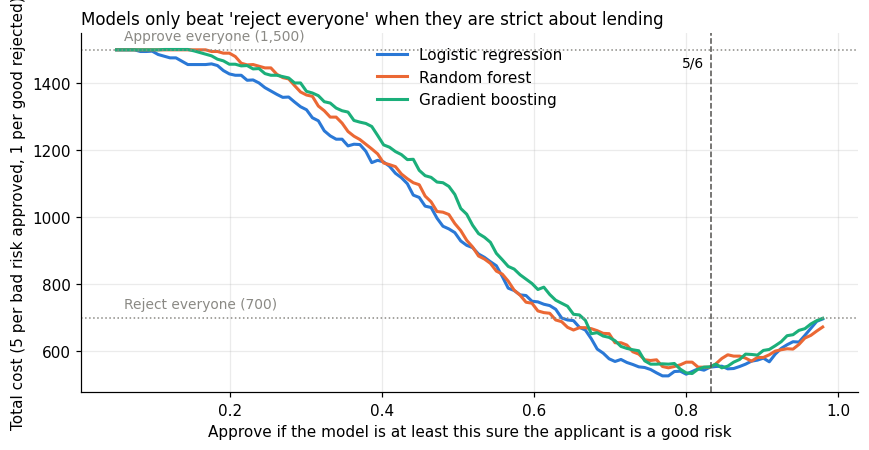

In [11]:
grid_t = np.linspace(0.05, 0.98, 120)
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, p in oof.items():
    costs = [evaluate(y, p > t)["cost"] for t in grid_t]
    ax.plot(grid_t, costs, lw=2, color=MODEL_COLOURS[name], label=name)
ax.axhline(1500, color=GREY, lw=1, ls=":"); ax.text(0.06, 1530, "Approve everyone (1,500)", color=GREY, fontsize=9)
ax.axhline(700, color=GREY, lw=1, ls=":");  ax.text(0.06, 730, "Reject everyone (700)", color=GREY, fontsize=9)
ax.axvline(THRESHOLD, color="#52514e", lw=1, ls="--"); ax.text(THRESHOLD - 0.01, 1450, "5/6", ha="right", fontsize=9)
ax.set_xlabel("Approve if the model is at least this sure the applicant is a good risk")
ax.set_ylabel("Total cost (5 per bad risk approved, 1 per good rejected)")
ax.set_title("Models only beat 'reject everyone' when they are strict about lending", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper center")
plt.tight_layout(); plt.show()

**Accuracy and cost pull in opposite directions.** At a 50% cut-off the models beat approve-everyone on accuracy, but they cost far more than rejecting everyone. At the 5/6 cut-off, cost drops well below 700, but accuracy falls *below* 70%, because the model turns away many good applicants to avoid the expensive bad ones. The bank's question is about money, so **cost decides. Accuracy is reported, not used to choose.**

### 1.5 Pick a model
**Question:** which one model should make the decisions?

**The rule, written down before looking at any fairness results:**
1. Find the cheapest model at 5/6.
2. Keep any model whose cost isn't *measurably* worse than the cheapest. We resample the applicants 2,000 times and look at the cost difference each time. If the middle 95% of differences includes 0, the gap could be luck.
3. Among the models left, prefer the one we can explain and audit: logistic regression, then gradient boosting, then random forest. A lender has to explain its decisions to applicants and regulators, and one readable weight per detail makes that possible.

Fairness is then checked for all three models anyway (section 2.2).

In [12]:
model_rows = results.loc[list(oof)]
cheapest = model_rows["cost"].astype(float).idxmin()
BOOT_SEL = np.random.default_rng(SEED).integers(0, len(y), size=(2000, len(y)))   # 2,000 resamples of the applicants
def boot_cost_of(a):
    A, Y = np.asarray(a)[BOOT_SEL], y.to_numpy()[BOOT_SEL]
    return 5 * ((Y == 0) & A).sum(1) + ((Y == 1) & ~A).sum(1)

cheap_boot = boot_cost_of(oof[cheapest] > THRESHOLD)
in_running = []
print(f"Cheapest model at 5/6: {cheapest} (cost {model_rows.loc[cheapest, 'cost']:,.0f})\n")
for name in oof:
    d = boot_cost_of(oof[name] > THRESHOLD) - cheap_boot
    lo, hi = np.percentile(d, [2.5, 97.5])
    ok = name == cheapest or lo <= 0 <= hi
    if ok:
        in_running.append(name)
    print(f"  {name:20s} cost {model_rows.loc[name, 'cost']:>5,.0f}   difference vs cheapest, 95% interval "
          f"{lo:+.0f} to {hi:+.0f}   ->  {'cheapest' if name == cheapest else 'not measurably worse' if ok else 'measurably worse'}")
d_rej = boot_cost_of(oof[cheapest] > THRESHOLD) - boot_cost_of(np.zeros(len(y), bool))
print(f"\n{cheapest} vs reject-everyone: cost difference {np.percentile(d_rej, 2.5):+.0f} to {np.percentile(d_rej, 97.5):+.0f} "
      f"(95% interval), so the saving is {'real' if np.percentile(d_rej, 97.5) < 0 else 'not clear'}.")

PREFERENCE = ["Logistic regression", "Gradient boosting", "Random forest"]     # most explainable first
BEST = next(m for m in PREFERENCE if m in in_running)
p_best = oof[BEST]
approve_best = p_best > THRESHOLD
print(f"\nChosen model: {BEST}")
print(f"  ROC AUC {results.loc[BEST, 'AUC']:.3f}, cost {results.loc[BEST, 'cost']:,.0f} "
      f"(vs 700 for reject-everyone, 1,500 for approve-everyone), accuracy {results.loc[BEST, 'accuracy']:.1%} at 5/6")

Cheapest model at 5/6: Logistic regression (cost 547)

  Logistic regression  cost   547   difference vs cheapest, 95% interval +0 to +0   ->  cheapest
  Random forest        cost   553   difference vs cheapest, 95% interval -43 to +57   ->  not measurably worse
  Gradient boosting    cost   552   difference vs cheapest, 95% interval -42 to +55   ->  not measurably worse

Logistic regression vs reject-everyone: cost difference -215 to -85 (95% interval), so the saving is real.

Chosen model: Logistic regression
  ROC AUC 0.787, cost 547 (vs 700 for reject-everyone, 1,500 for approve-everyone), accuracy 58.5% at 5/6


**The three models side by side.** **Question:** what does each model do well and badly, judged on this data?

In [13]:
overfit = {n: train_acc[n] - evaluate(y, p > 0.5)["accuracy"] for n, p in oof.items()}
yv = y.to_numpy()
def good_risk_gap(p):
    a = p > THRESHOLD
    return 100 * (a[~young & (yv == 1)].mean() - a[young & (yv == 1)].mean())
comparison = pd.DataFrame({
    "Logistic regression": {
        "How it works": "adds up one weight per detail, then turns the total into a probability",
        "Interpretability": "high: every weight can be read directly (section 3.2)",
        "Non-linear patterns and combinations": "no, unless we add them by hand",
        "Computational cost": "lowest: trains in a blink"},
    "Random forest": {
        "How it works": "hundreds of decision trees, each trained on a random slice of the data, vote",
        "Interpretability": "low: needs indirect tools such as permutation importance",
        "Non-linear patterns and combinations": "yes",
        "Computational cost": "medium"},
    "Gradient boosting": {
        "How it works": "small trees built one after another, each fixing the last one's mistakes",
        "Interpretability": "low: needs indirect tools such as permutation importance",
        "Non-linear patterns and combinations": "yes (here trees 2 to 3 levels deep, so combinations of 2 to 3 details)",
        "Computational cost": "medium"},
}).T
comparison["ROC AUC (unseen data)"] = [f"{results.loc[n, 'AUC']:.3f}" for n in comparison.index]
comparison["Cost at 5/6"] = [f"{results.loc[n, 'cost']:,.0f}" for n in comparison.index]
comparison["Overfitting (training minus unseen accuracy)"] = [f"{overfit[n]:.1%}" for n in comparison.index]
comparison["Age gap among good risks (points)"] = [f"{good_risk_gap(oof[n]):+.1f}" for n in comparison.index]
comparison["Brier score (lower = more honest probabilities)"] = [f"{scorecard.loc[n, 'Brier score']:.3f}" for n in comparison.index]
display(comparison.T.style.set_properties(**{"text-align": "left", "white-space": "normal"}))

,Logistic regression,Random forest,Gradient boosting
How it works,"adds up one weight per detail, then turns the total into a probability","hundreds of decision trees, each trained on a random slice of the data, vote","small trees built one after another, each fixing the last one's mistakes"
Interpretability,high: every weight can be read directly (section 3.2),low: needs indirect tools such as permutation importance,low: needs indirect tools such as permutation importance
Non-linear patterns and combinations,"no, unless we add them by hand",yes,"yes (here trees 2 to 3 levels deep, so combinations of 2 to 3 details)"
Computational cost,lowest: trains in a blink,medium,medium
ROC AUC (unseen data),0.787,0.777,0.767
Cost at 5/6,547,553,552
Overfitting (training minus unseen accuracy),3.9%,20.4%,8.8%
Age gap among good risks (points),+19.5,+31.8,+26.9
Brier score (lower = more honest probabilities),0.165,0.166,0.170


## 2. Fairness: does the model treat under-25s differently?

We measure three things for each age group:

1. **Approval rate**: what share of the group gets a loan.
2. **Approval rate among good risks** (*equal opportunity*, **our main fairness measure**): of the people who *really did* pay back, what share got a loan? If this differs, the model is turning away reliable young people more often. We lead with this because it asks exactly our question (are creditworthy under-25s penalised?) and, unlike equal approval rates, it doesn't punish a model for real differences in repayment. Its weakness: it trusts the good/bad labels. These record whether each loan was actually repaid, so they are real outcomes, but only for people the bank chose to lend to in the first place (section 6.2).
3. **Actual good-risk rate**: what really happened. This shows how much of the gap reflects real differences in repayment.

We also show the **ratio** of approval rates. A ratio below **0.8** is the "four-fifths rule": a US rule of thumb from employment law, used here as a yardstick, **not a UK legal test**.

Because only about 150 applicants are under 25, any gap could partly be luck. **Bootstrapping** handles this: we resample the applicants 2,000 times, recompute the gap each time, and the middle 95% of results gives a confidence interval.

In [14]:
def group_metrics(approve, y, young):
    y, approve = np.asarray(y), np.asarray(approve).astype(bool)
    out = {}
    for label, g in [("Under 25", young), ("25 or older", ~young)]:
        out[label] = {"approval rate": approve[g].mean(),
                      "approval rate among good risks": approve[g & (y == 1)].mean(),
                      "actual good-risk rate": y[g].mean()}
    return pd.DataFrame(out).T

def bootstrap_gaps(approve, y, young, n=2000, seed=SEED):
    # 95% intervals for the gaps (25+ minus under-25) and for the approval ratio.
    r = np.random.default_rng(seed)
    y, approve = np.asarray(y), np.asarray(approve).astype(float)
    idx = r.integers(0, len(y), size=(n, len(y)))
    A, Y, G = approve[idx], y[idx], young[idx]
    def rate(mask, vals):
        return (vals * mask).sum(1) / mask.sum(1)
    old_app, yng_app = rate(~G, A), rate(G, A)
    old_eo, yng_eo = rate(~G & (Y == 1), A), rate(G & (Y == 1), A)
    stats = {"approval gap": old_app - yng_app,
             "good-risk approval gap": old_eo - yng_eo,
             "approval ratio (young / older)": yng_app / old_app}
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in stats.items()}

def fairness_summary(approve):
    gm = group_metrics(approve, y, young)
    ci = bootstrap_gaps(approve, y, young)
    point = {"approval gap": gm.loc["25 or older", "approval rate"] - gm.loc["Under 25", "approval rate"],
             "good-risk approval gap": gm.loc["25 or older", "approval rate among good risks"]
                                        - gm.loc["Under 25", "approval rate among good risks"],
             "approval ratio (young / older)": gm.loc["Under 25", "approval rate"] / gm.loc["25 or older", "approval rate"]}
    return gm, point, ci

gm, point, ci = fairness_summary(approve_best)
print(f"Model: {BEST}, threshold 5/6\n")
display(gm.style.format("{:.1%}"))
for k in point:
    fmt = (lambda v: f"{v:.2f}") if "ratio" in k else (lambda v: f"{v * 100:+.1f} percentage points")
    print(f"{k:32s} {fmt(point[k])}   (95% CI {fmt(ci[k][0])} to {fmt(ci[k][1])})")

Model: Logistic regression, threshold 5/6



,approval rate,approval rate among good risks,actual good-risk rate
Under 25,18.8%,28.4%,59.1%
25 or older,38.0%,47.9%,71.9%


approval gap                     +19.2 percentage points   (95% CI +12.0 percentage points to +26.1 percentage points)
good-risk approval gap           +19.5 percentage points   (95% CI +8.8 percentage points to +29.7 percentage points)
approval ratio (young / older)   0.50   (95% CI 0.33 to 0.68)


**Chart: how each age group is treated.** Error bars show the 95% bootstrap confidence interval for each rate.

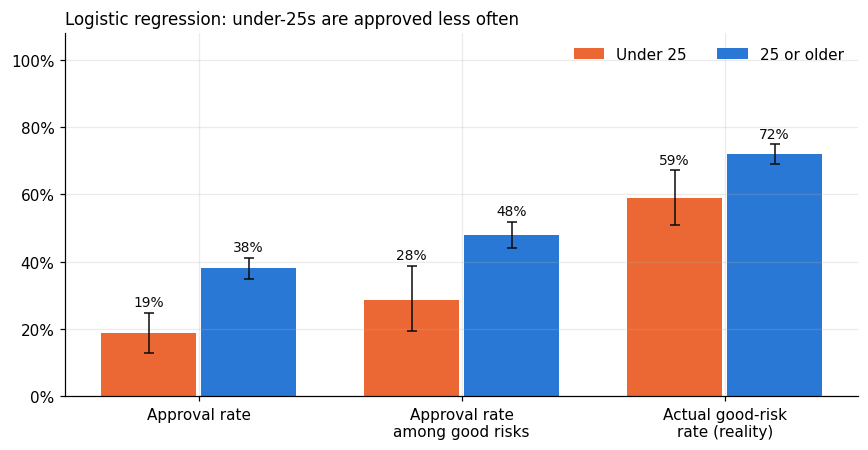

In [15]:
def rate_ci(values, mask, n=2000, seed=SEED):
    r = np.random.default_rng(seed)
    v = np.asarray(values, dtype=float)[mask]
    boots = r.choice(v, size=(n, len(v))).mean(1)
    return v.mean(), *np.percentile(boots, [2.5, 97.5])

yv = y.to_numpy()
metrics = [("Approval rate", approve_best, np.ones(len(yv), bool)),
           ("Approval rate\namong good risks", approve_best, yv == 1),
           ("Actual good-risk\nrate (reality)", yv, np.ones(len(yv), bool))]
fig, ax = plt.subplots(figsize=(8, 4.2))
bar_w = 0.36   # bar width (named so it doesn't overwrite the reweighing weights `w` in section 5)
for j, (label, g, colour) in enumerate([("Under 25", young, ORANGE), ("25 or older", ~young, BLUE)]):
    for i, (_, vals, extra) in enumerate(metrics):
        m, lo, hi = rate_ci(vals, g & extra)
        x = i + (j - 0.5) * (bar_w + 0.02)
        ax.bar(x, m, width=bar_w, color=colour, label=label if i == 0 else None)
        ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], color="#0b0b0b", capsize=3, lw=1)
        ax.text(x, hi + 0.02, f"{m:.0%}", ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(range(len(metrics))); ax.set_xticklabels([m[0] for m in metrics])
ax.set_ylim(0, 1.08); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title(f"{BEST}: under-25s are approved less often", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper right", ncol=2)
plt.tight_layout(); plt.show()

### 2.1 Is the gap bigger than reality?
Compare the **approval gap** with the **real difference in repayment**. If the model's gap is much bigger than the real difference, the strict 5/6 threshold is magnifying it. If it is similar, the gap mostly reflects the data, which still raises the question of whether the data itself is fair (section 6.2). We show both cut-offs, because the amplification depends on how strict the bank is.

In [16]:
real_gap = yv[~young].mean() - yv[young].mean()
print(f"Real difference in good-risk rate (25+ minus under 25): {real_gap * 100:+.1f} points")
for t, label in [(0.5, "50% cut-off"), (THRESHOLD, "5/6 cut-off")]:
    a = p_best > t
    g = a[~young].mean() - a[young].mean()
    print(f"Model's approval gap at the {label:11s}: {g * 100:+.1f} points = {g / real_gap:.2f}x the real difference")

Real difference in good-risk rate (25+ minus under 25): +12.9 points
Model's approval gap at the 50% cut-off: +14.9 points = 1.16x the real difference
Model's approval gap at the 5/6 cut-off: +19.2 points = 1.49x the real difference


### 2.2 Fairness for all three models
The model comparison from section 1, judged on all three things: **accuracy, cost and fairness**. **Question:** is the most accurate model also the fairest?

In [17]:
compare = {}
for name, p in oof.items():
    a = p > THRESHOLD
    _, pt, c = fairness_summary(a)
    compare[name] = {"accuracy (50% threshold)": results.loc[name, "accuracy at 50% threshold"],
                     "accuracy": results.loc[name, "accuracy"], "cost": results.loc[name, "cost"],
                     "approval gap (points)": pt["approval gap"] * 100,
                     "gap 95% CI": f"{c['approval gap'][0] * 100:+.0f} to {c['approval gap'][1] * 100:+.0f}",
                     "good-risk approval gap (points)": pt["good-risk approval gap"] * 100,
                     "approval ratio": pt["approval ratio (young / older)"]}
pd.DataFrame(compare).T.style.format({"accuracy (50% threshold)": "{:.1%}", "accuracy": "{:.1%}", "cost": "{:,.0f}", "approval gap (points)": "{:+.1f}",
                                      "good-risk approval gap (points)": "{:+.1f}", "approval ratio": "{:.2f}"})

,accuracy (50% threshold),accuracy,cost,approval gap (points),gap 95% CI,good-risk approval gap (points),approval ratio
Logistic regression,75.0%,58.5%,547,+19.2,+12 to +26,+19.5,0.50
Random forest,75.8%,55.5%,553,+24.5,+18 to +30,+31.8,0.29
Gradient boosting,74.0%,57.6%,552,+21.8,+15 to +28,+26.9,0.41


### 2.3 Does a stricter bank create a bigger gap?
The threshold is a business choice. This chart shows the approval rate for each age group, and the gap between them, as the bank becomes stricter.

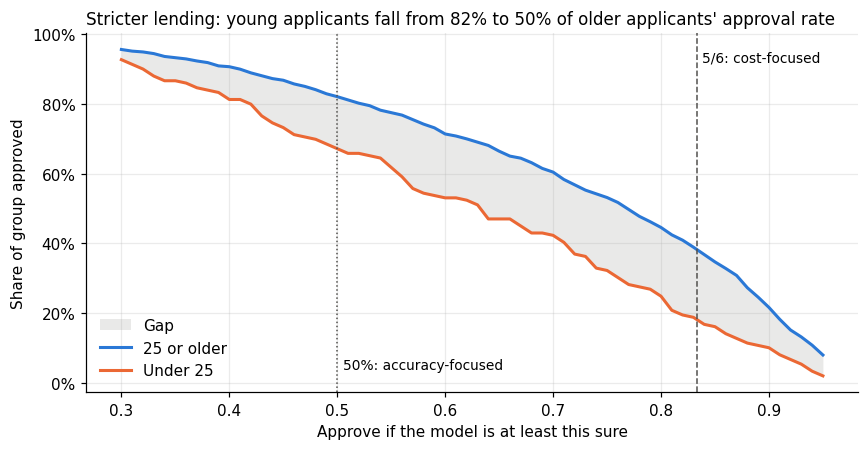

50% threshold: under 25 67.1%, 25+ 82.0%, gap 14.9 points, ratio 0.82
5/6 threshold: under 25 18.8%, 25+ 38.0%, gap 19.2 points, ratio 0.50


In [18]:
ts = np.linspace(0.3, 0.95, 66)
yr = [(p_best[young] > t).mean() for t in ts]
orr = [(p_best[~young] > t).mean() for t in ts]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(ts, yr, orr, color=GREY, alpha=0.18, lw=0, label="Gap")
ax.plot(ts, orr, color=BLUE, lw=2, label="25 or older")
ax.plot(ts, yr, color=ORANGE, lw=2, label="Under 25")
ax.axvline(0.5, color="#52514e", lw=1, ls=":"); ax.text(0.505, 0.04, "50%: accuracy-focused", fontsize=9)
ax.axvline(THRESHOLD, color="#52514e", lw=1, ls="--"); ax.text(THRESHOLD + 0.005, 0.92, "5/6: cost-focused", fontsize=9)
ax.set_xlabel("Approve if the model is at least this sure"); ax.set_ylabel("Share of group approved")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
r50 = (p_best[young] > 0.5).mean() / (p_best[~young] > 0.5).mean()
r56 = (p_best[young] > THRESHOLD).mean() / (p_best[~young] > THRESHOLD).mean()
ax.set_title(f"Stricter lending: young applicants fall from {r50:.0%} to {r56:.0%} of older applicants' approval rate", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

for t, label in [(0.5, "50% threshold"), (THRESHOLD, "5/6 threshold")]:
    a_y, a_o = (p_best[young] > t).mean(), (p_best[~young] > t).mean()
    print(f"{label}: under 25 {a_y:.1%}, 25+ {a_o:.1%}, gap {100 * (a_o - a_y):.1f} points, ratio {a_y / a_o:.2f}")

### 2.4 Why 25, and does the result depend on it?
**Why 25:** it's a convention from fairness research on this dataset, not a natural boundary. Kamiran and Calders (2009) split it at **25 or younger** vs older, and IBM's AI Fairness 360 toolkit has used both that split and **under 25** vs 25 and over in its German Credit examples. We use under 25 (149 people); "25 or younger" gives 190.

**Question:** would a different line change the answer? We re-run the audit at every cut-off from 22 to 35, chosen in advance. If the gap only showed up at one cut-off, the finding would be fragile, and picking whichever cut-off gave the biggest gap would be cherry-picking.

In [19]:
ages_all = X["age"].to_numpy()
cut_rows = []
for c in range(22, 36):
    g = ages_all < c
    a = p_best > THRESHOLD
    cut_rows.append({"younger group": f"under {c}" + ("  (= 25 or younger)" if c == 26 else "  (ours)" if c == 25 else ""),
                     "people in group": int(g.sum()),
                     "approved (count)": int(a[g].sum()), "rejected (count)": int((~a[g]).sum()),
                     "approved, younger": a[g].mean(), "approved, older": a[~g].mean(),
                     "approval gap (points)": 100 * (a[~g].mean() - a[g].mean()),
                     "good-risk approval gap (points)": 100 * (a[~g & (yv == 1)].mean() - a[g & (yv == 1)].mean()),
                     "ratio": a[g].mean() / a[~g].mean()})
cuts = pd.DataFrame(cut_rows).set_index("younger group")
display(cuts.style.format({"approved, younger": "{:.1%}", "approved, older": "{:.1%}", "approval gap (points)": "{:.1f}",
                           "good-risk approval gap (points)": "{:.1f}", "ratio": "{:.2f}"}))
print(f"Approval gap ranges from {cuts['approval gap (points)'].min():.1f} to {cuts['approval gap (points)'].max():.1f} points; "
      f"ratio from {cuts['ratio'].min():.2f} to {cuts['ratio'].max():.2f}. The smallest groups (under 22: {cuts['people in group'].iloc[0]} people) "
      f"are the least reliable.")

,people in group,approved (count),rejected (count),"approved, younger","approved, older",approval gap (points),good-risk approval gap (points),ratio
younger group,,,,,,,,
under 22,30,6,24,20.0%,35.6%,15.6,14.2,0.56
under 23,57,10,47,17.5%,36.2%,18.6,26.8,0.49
under 24,105,19,86,18.1%,37.1%,19.0,22.0,0.49
under 25 (ours),149,28,121,18.8%,38.0%,19.2,19.5,0.50
under 26 (= 25 or younger),190,37,153,19.5%,38.8%,19.3,20.5,0.50
under 27,240,53,187,22.1%,39.2%,17.1,17.6,0.56
under 28,291,66,225,22.7%,40.2%,17.5,18.9,0.56
under 29,334,77,257,23.1%,41.1%,18.1,19.8,0.56
under 30,371,88,283,23.7%,41.8%,18.1,19.5,0.57


Approval gap ranges from 15.6 to 19.5 points; ratio from 0.49 to 0.62. The smallest groups (under 22: 30 people) are the least reliable.


**Age bands, with counts.** **Question:** is the pattern a single cliff at 25, or a steady climb with age?

The bands are fixed in advance at life stages (under 25, 25–29, 30–39, 40–59, 60+), not chosen to make any gap look bigger. Every rate comes with the number of people behind it and a 95% interval, because a rate based on 38 people deserves much less trust than one based on 300.

In [20]:
AGE_BANDS = [("Under 25", 0, 25), ("25–29", 25, 30), ("30–39", 30, 40), ("40–59", 40, 60), ("60 or older", 60, 200)]
r_band = np.random.default_rng(SEED)
band_n_rows, band_boot = [], {}
for name, lo_age, hi_age in AGE_BANDS:
    m = (ages_all >= lo_age) & (ages_all < hi_age)
    a = approve_best[m]
    boots = r_band.choice(a.astype(float), size=(2000, m.sum())).mean(1)
    band_boot[name] = boots
    band_n_rows.append({"age band": name, "applicants": int(m.sum()), "approved": int(a.sum()), "rejected": int((~a).sum()),
                        "approval rate": a.mean(),
                        "95% interval": f"{np.percentile(boots, 2.5):.0%} to {np.percentile(boots, 97.5):.0%}",
                        "actually repaid": yv[m].mean(),
                        "repaid, of whom approved": f"{int(approve_best[m & (yv == 1)].sum())} of {int((m & (yv == 1)).sum())}"})
age_bands = pd.DataFrame(band_n_rows).set_index("age band")
display(age_bands.style.format({"approval rate": "{:.1%}", "actually repaid": "{:.1%}"}))
d = band_boot["25–29"] - band_boot["Under 25"]
lo, hi = np.percentile(d, [2.5, 97.5])
print(f"Approval rises from {age_bands['approval rate'].iloc[0]:.0%} (under 25) to {age_bands['approval rate'].max():.0%} "
      f"(highest band); actual repayment rises from {age_bands['actually repaid'].iloc[0]:.0%} to {age_bands['actually repaid'].max():.0%}.")
print(f"Under 25 vs 25–29: approval difference {100 * d.mean():+.1f} points (95% interval {100 * lo:+.1f} to {100 * hi:+.1f})"
      + ("  ->  within noise" if lo < 0 < hi else "  ->  a real difference") + ".")

,applicants,approved,rejected,approval rate,95% interval,actually repaid,"repaid, of whom approved"
age band,,,,,,,
Under 25,149,28,121,18.8%,13% to 25%,59.1%,25 of 88
25–29,222,60,162,27.0%,21% to 33%,65.8%,51 of 146
30–39,330,129,201,39.1%,34% to 44%,74.2%,121 of 245
40–59,248,111,137,44.8%,39% to 51%,73.8%,101 of 183
60 or older,51,23,28,45.1%,31% to 59%,74.5%,20 of 38


Approval rises from 19% (under 25) to 45% (highest band); actual repayment rises from 59% to 75%.
Under 25 vs 25–29: approval difference +8.3 points (95% interval -0.5 to +16.6)  ->  within noise.


**What this can and can't tell us.** The bands show how approval and actual repayment move together with age. They don't tell us whether *age itself* or details that come with age (job length, savings, housing) drive the gap. Sections 3 and 6.3.2 separate those.

### 2.5 The numbers the brief asks for
**Question:** what are the headline fairness numbers at each cut-off?
Reported at both operating points, because accuracy and cost disagree about which threshold is best.

In [21]:
print(f"REPORT: {BEST}\n")
for t, label in [(0.5, "Accuracy-focused (50% threshold)"), (THRESHOLD, "Cost-focused (5/6 threshold, from the 5:1 rule)")]:
    a = p_best > t
    ev = evaluate(y, a)
    gm_t, pt_t, ci_t = fairness_summary(a)
    print(label)
    print(f"  Accuracy:                    {ev['accuracy']:.1%}   (approve-everyone: 70.0%)")
    print(f"  Cost:                        {ev['cost']:,}   (approve-everyone: 1,500; reject-everyone: 700)")
    print(f"  Approval rate, under 25:     {gm_t.loc['Under 25', 'approval rate']:.1%}")
    print(f"  Approval rate, 25 or older:  {gm_t.loc['25 or older', 'approval rate']:.1%}")
    print(f"  Gap:                         {pt_t['approval gap'] * 100:.1f} percentage points "
          f"(95% CI {ci_t['approval gap'][0] * 100:.1f} to {ci_t['approval gap'][1] * 100:.1f})")
    print(f"  Ratio (young / older):       {pt_t['approval ratio (young / older)']:.2f}   (below 0.80 = red flag)")
    print(f"  MAIN MEASURE - approved among good risks: under 25 {gm_t.loc['Under 25', 'approval rate among good risks']:.1%}, "
          f"25+ {gm_t.loc['25 or older', 'approval rate among good risks']:.1%}, gap {pt_t['good-risk approval gap'] * 100:.1f} points "
          f"(95% CI {ci_t['good-risk approval gap'][0] * 100:.1f} to {ci_t['good-risk approval gap'][1] * 100:.1f})\n")

REPORT: Logistic regression

Accuracy-focused (50% threshold)
  Accuracy:                    75.0%   (approve-everyone: 70.0%)
  Cost:                        946   (approve-everyone: 1,500; reject-everyone: 700)
  Approval rate, under 25:     67.1%
  Approval rate, 25 or older:  82.0%
  Gap:                         14.9 percentage points (95% CI 7.2 to 23.0)
  Ratio (young / older):       0.82   (below 0.80 = red flag)
  MAIN MEASURE - approved among good risks: under 25 78.4%, 25+ 90.7%, gap 12.3 points (95% CI 3.9 to 21.5)

Cost-focused (5/6 threshold, from the 5:1 rule)
  Accuracy:                    58.5%   (approve-everyone: 70.0%)
  Cost:                        547   (approve-everyone: 1,500; reject-everyone: 700)
  Approval rate, under 25:     18.8%
  Approval rate, 25 or older:  38.0%
  Gap:                         19.2 percentage points (95% CI 12.0 to 26.1)
  Ratio (young / older):       0.50   (below 0.80 = red flag)
  MAIN MEASURE - approved among good risks: under 25 28.4%

### 2.6 What if bad loans were as rare as in real life?
The data has 30% bad loans, but the real rate is reported to be about 5%. The model learned from the 30% version, so it is too pessimistic about everyone. Correcting its odds to a 5% base rate, the same 5:1 rule ("lend above 5/6") becomes a much lower cut-off on the model's scores. So the 0.50 ratio is a result **for this oversampled data**: a real bank would be less strict, and the gap smaller.

**Assumptions:** this correction relies on the bad loans being sampled by outcome (Grömping reports the sample was stratified, with bad loans heavily oversampled) and on the model's probabilities being calibrated (section 6.3.1). The 5% figure comes from Grömping (2019) relaying the original German sources, so treat it as approximate.

In [22]:
REAL_BAD = 0.05
data_bad = 1 - yv.mean()
# odds of 'good' scale by (real good:bad odds) / (data good:bad odds)
odds_factor = ((1 - REAL_BAD) / REAL_BAD) / ((1 - data_bad) / data_bad)
odds_needed = (THRESHOLD / (1 - THRESHOLD)) / odds_factor
T_REAL = odds_needed / (1 + odds_needed)
a_real = p_best > T_REAL
gm_r, pt_r, ci_r = fairness_summary(a_real)
print(f"Equivalent cut-off on the model's scores at a {REAL_BAD:.0%} bad rate: {T_REAL:.2f} (vs {THRESHOLD:.2f})")
print(f"Approved: under 25 {gm_r.loc['Under 25', 'approval rate']:.1%}, 25+ {gm_r.loc['25 or older', 'approval rate']:.1%}")
print(f"Approval gap {pt_r['approval gap'] * 100:.1f} points (95% CI {ci_r['approval gap'][0] * 100:.1f} to {ci_r['approval gap'][1] * 100:.1f})")
print(f"Ratio {pt_r['approval ratio (young / older)']:.2f} (95% CI {ci_r['approval ratio (young / older)'][0]:.2f} to {ci_r['approval ratio (young / older)'][1]:.2f})")
print(f"Good-risk gap {pt_r['good-risk approval gap'] * 100:.1f} points (95% CI {ci_r['good-risk approval gap'][0] * 100:.1f} to {ci_r['good-risk approval gap'][1] * 100:.1f})")

Equivalent cut-off on the model's scores at a 5% bad rate: 0.38 (vs 0.83)
Approved: under 25 83.9%, 25+ 91.8%
Approval gap 7.9 points (95% CI 2.1 to 14.3)
Ratio 0.91 (95% CI 0.85 to 0.98)
Good-risk gap 4.5 points (95% CI -0.9 to 11.1)


## 3. What drives the gap?

We explain **logistic regression**: our chosen model, and the one whose reasoning we can read directly.

Logistic regression gives every applicant a **score**: a weighted sum of their details. Higher score means more likely to be approved. Because the score is just a sum, the difference in *average* score between older and younger applicants splits exactly into one piece per detail:

$$\text{gap from a detail} = \text{weight} \times \text{(how much the groups differ on it)}$$

So a detail only drives the gap if the model cares about it (large weight) **and** young and older applicants differ on it.

**Question:** which details push young applicants' scores down? (Scores are in log-odds: +0.2 means the odds of repaying are multiplied by about 1.22.)

In [23]:
# Fit logistic regression on all 1,000 applicants (settings tuned by cross-validation) so we can read its weights
lr_pipe, lr_grid = make_models()["Logistic regression"]
lr_full = GridSearchCV(lr_pipe, lr_grid, cv=INNER, scoring="neg_log_loss").fit(X, y).best_estimator_
prep, lr = lr_full.named_steps["prep"], lr_full.named_steps["model"]
Z = prep.transform(X)
col_names = prep.get_feature_names_out()

def original_feature(name):
    kind, rest = name.split("__", 1)
    if kind == "num":
        return rest
    return max((c for c in CAT if rest.startswith(c + "_")), key=len)

def p_good(df):
    """The fitted logistic regression's chance that each applicant repays."""
    return lr_full.predict_proba(df[COLS])[:, 1]

contrib = pd.Series(lr.coef_[0] * (Z[~young].mean(0) - Z[young].mean(0)), index=col_names)
by_feature = contrib.groupby([original_feature(n) for n in col_names]).sum().sort_values()
score = Z @ lr.coef_[0]
print(f"Average score gap (25+ minus under 25): {score[~young].mean() - score[young].mean():.3f}")
print(f"Sum of the per-detail pieces:            {by_feature.sum():.3f}   (they match exactly)")

Average score gap (25+ minus under 25): 0.614
Sum of the per-detail pieces:            0.614   (they match exactly)


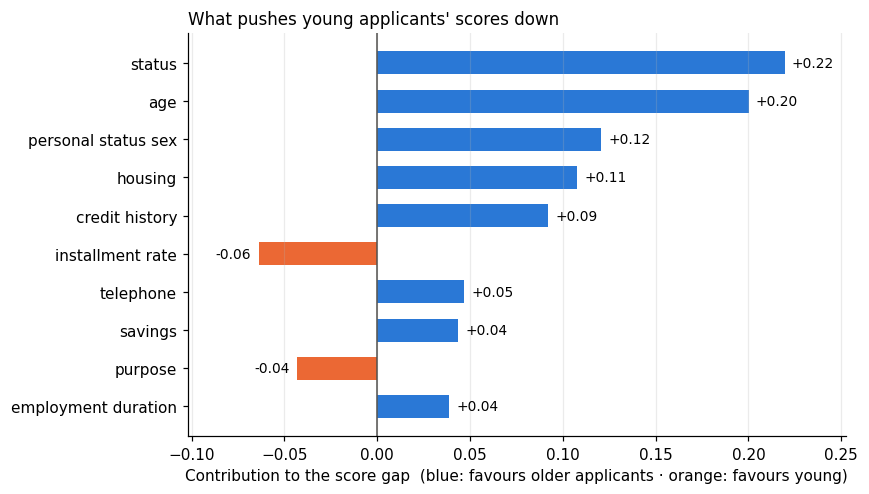

In [24]:
top = by_feature.reindex(by_feature.abs().sort_values().index)[-10:]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index.str.replace("_", " "), top.values, color=[BLUE if v > 0 else ORANGE for v in top.values], height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlim(min(top.min() * 1.6, -0.05), top.max() * 1.15)
for i, v in enumerate(top.values):
    ax.text(v + (0.004 if v > 0 else -0.004), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.set_xlabel("Contribution to the score gap  (blue: favours older applicants · orange: favours young)")
ax.set_title("What pushes young applicants' scores down", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Question:** how do young and older applicants actually differ on the top drivers? For each one, the category where the two groups differ most (or the average, for real numbers):

In [25]:
rows = []
for f in by_feature.abs().sort_values(ascending=False).index[:6]:
    if f in NUM and f not in ORDINAL:
        rows.append({"detail": f.replace("_", " "), "value": "average", "under 25": f"{X.loc[young, f].mean():.1f}",
                     "25 or older": f"{X.loc[~young, f].mean():.1f}"})
    else:
        share_y = X.loc[young, f].value_counts(normalize=True)
        share_o = X.loc[~young, f].value_counts(normalize=True)
        diff = (share_y.reindex(share_o.index, fill_value=0) - share_o).abs()
        cat = diff.idxmax()
        rows.append({"detail": f.replace("_", " "), "value": show_value(f, cat), "under 25": f"{share_y.get(cat, 0):.0%}",
                     "25 or older": f"{share_o[cat]:.0%}"})
pd.DataFrame(rows).set_index("detail")

,value,under 25,25 or older
detail,,,
status,>= 200 DM or salary account,26%,42%
age,average,22.6,37.8
personal status sex,male: married/widowed,28%,59%
housing,lives for free,46%,13%
credit history,no credits or all paid back duly,74%,49%
installment rate,1 (band 1 of 4),21%,12%


### 3.1 Is the gap justified?
A useful way to judge each driver is to ask **"does this detail measure whether someone can repay, or just how far along in life they are?"**

- **Repayment-related** (stronger case for using them): checking account balance, credit history, loan size and length.
- **Life-stage related** (weaker case): age itself, years in current job, years at current address, housing (renting, owning or living for free), family status. Young people score badly on these almost by definition, even if they are reliable.

If a large share of the gap comes from life-stage details, the model is partly penalising people **for being young**, not for being risky. Section 4 tests this directly.

### 3.2 Weightings: what each model relies on
**Question:** which details drive the predictions, how strongly, in which direction, and do the three models agree?

The three models store what they learned in different ways, so each gets a measure that suits it. **These measures are not on the same scale**, so don't compare a logistic regression odds ratio with a tree's importance score.

| Measure | Plain English | Technical meaning | Used for |
|---|---|---|---|
| **Odds ratio** | "Having this multiplies the odds of repaying by x." Above 1 helps, below 1 hurts. | exp(coefficient). For number details, per one standard deviation up. For categories, compared with the model's average category (every category is kept and the penalty shrinks them towards 0). | Logistic regression |
| **Spread of contribution** | How much this detail moves people's scores, from the person it helps most to the person it hurts most. | Standard deviation across applicants of (coefficient × value), summed over the detail's categories, in log-odds. | Logistic regression |
| **Permutation importance** | We shuffle one detail, say savings, among the test applicants, and see how much worse the model gets at telling repayers from non-repayers. A big drop means the model really used that detail. | Fall in ROC AUC on the held-out fold when one column is randomly shuffled, averaged over 10 shuffles and 5 folds. | All three models, same scale |

**Two warnings.**
1. **Importance means prediction, not cause.** If savings matters to the model, that doesn't prove that having savings *makes* people repay.
2. **Overlapping details share the credit.** When two details carry similar information (housing and property, say), shuffling one barely hurts because the other still carries it, so both can look less important than they are.

We don't use the trees' built-in importance scores, because they favour details with many categories. We don't use SHAP either: for logistic regression, SHAP values come down to coefficient × (value minus average), which is exactly what sections 3 and 3.3 already show, and for the trees, permutation importance answers the question we need.

In [26]:
# Logistic regression (trained on all 1,000, settings tuned by cross-validation; section 3): odds ratios
coef = pd.Series(lr.coef_[0], index=col_names)
def nice_term(n):
    f = original_feature(n)
    if n.startswith("num__"):
        return f.replace("_", " ") + " (1 standard deviation higher)"
    return f.replace("_", " ") + ": " + n.split("__", 1)[1][len(f) + 1:]
terms = pd.DataFrame({"term": [nice_term(n) for n in col_names], "coefficient (log-odds)": coef.values,
                      "odds ratio": np.exp(coef.values)}, index=col_names)
terms["direction"] = np.where(terms["coefficient (log-odds)"] > 0, "raises the odds of repaying", "lowers the odds of repaying")

# Stability: the same terms in the 5 models trained during cross-validation (each saw a different 800 people)
fold_coefs = pd.DataFrame([pd.Series(m.named_steps["model"].coef_[0], index=m.named_steps["prep"].get_feature_names_out())
                           for m in FOLD_MODELS["Logistic regression"]])
terms["fold sd"] = fold_coefs.std()
terms["same direction in all 5 folds"] = (np.sign(fold_coefs) == np.sign(coef)).all().map({True: "yes", False: "NO"})
top_terms = terms.reindex(terms["coefficient (log-odds)"].abs().sort_values(ascending=False).index).head(15)
print("Logistic regression: the 15 strongest terms")
display(top_terms.set_index("term")[["odds ratio", "coefficient (log-odds)", "fold sd", "same direction in all 5 folds", "direction"]]
        .style.format({"odds ratio": "{:.2f}", "coefficient (log-odds)": "{:+.2f}", "fold sd": "{:.2f}"}))
print(f"{(top_terms['same direction in all 5 folds'] == 'yes').sum()} of the 15 strongest terms point the same way in all 5 cross-validation models.")
print("Number details (duration, amount, age and the 1-4 codes) are per 1 standard deviation. Installment rate's direction is disputed (section 6.2).\n")

# Spread of contribution per detail
contrib_each = pd.DataFrame(Z * lr.coef_[0], columns=col_names)
spread = contrib_each.T.groupby([original_feature(n) for n in col_names]).sum().T.std().sort_values(ascending=False)
lr_weight = pd.DataFrame({"spread of contribution (log-odds)": spread, "relative weight": spread / spread.sum()})
lr_weight.index = lr_weight.index.str.replace("_", " ")
print("Logistic regression: how much each detail moves people's scores")
display(lr_weight.head(10).style.format({"spread of contribution (log-odds)": "{:.2f}", "relative weight": "{:.0%}"}))

Logistic regression: the 15 strongest terms


,odds ratio,coefficient (log-odds),fold sd,same direction in all 5 folds,direction
term,,,,,
status: >= 200 DM or salary account,2.18,+0.78,0.08,yes,raises the odds of repaying
status: no checking account,0.54,-0.61,0.06,yes,lowers the odds of repaying
credit history: all credits at this bank paid duly,1.77,+0.57,0.06,yes,raises the odds of repaying
purpose: car (new),1.68,+0.52,0.16,yes,raises the odds of repaying
purpose: other,0.62,-0.48,0.11,yes,lowers the odds of repaying
savings: unknown / no savings account,0.65,-0.42,0.10,yes,lowers the odds of repaying
employment duration: 4-7 years,1.42,+0.35,0.12,yes,raises the odds of repaying
credit history: critical account / credits elsewhere,0.71,-0.34,0.11,yes,lowers the odds of repaying
other debtors: guarantor,1.39,+0.33,0.24,yes,raises the odds of repaying


15 of the 15 strongest terms point the same way in all 5 cross-validation models.
Number details (duration, amount, age and the 1-4 codes) are per 1 standard deviation. Installment rate's direction is disputed (section 6.2).

Logistic regression: how much each detail moves people's scores


,spread of contribution (log-odds),relative weight
status,0.60,15%
purpose,0.31,8%
duration,0.31,8%
installment rate,0.30,8%
savings,0.30,8%
credit history,0.29,8%
amount,0.27,7%
personal status sex,0.21,5%
other installment plans,0.18,5%
employment duration,0.18,5%


Logistic regression: permutation importance done
Random forest: permutation importance done
Gradient boosting: permutation importance done


,LR: AUC drop,LR: fold sd,LR: rank,RF: AUC drop,RF: fold sd,RF: rank,GB: AUC drop,GB: fold sd,GB: rank
status,0.089,0.013,1,0.128,0.021,1,0.112,0.011,1
duration,0.021,0.010,4,0.027,0.004,2,0.033,0.006,2
credit history,0.021,0.010,3,0.019,0.009,4,0.023,0.007,3
amount,0.014,0.006,7,0.021,0.012,3,0.011,0.009,5
purpose,0.021,0.006,2,0.003,0.005,9,0.019,0.004,4
savings,0.016,0.010,6,0.012,0.008,5,0.010,0.010,6
installment rate,0.017,0.006,5,0.004,0.007,8,0.003,0.003,9
other installment plans,0.006,0.003,10,0.007,0.007,6,0.009,0.005,7
age,0.004,0.004,11,0.005,0.008,7,0.006,0.004,8
personal status sex,0.011,0.006,8,0.001,0.007,14,0.000,0.002,14


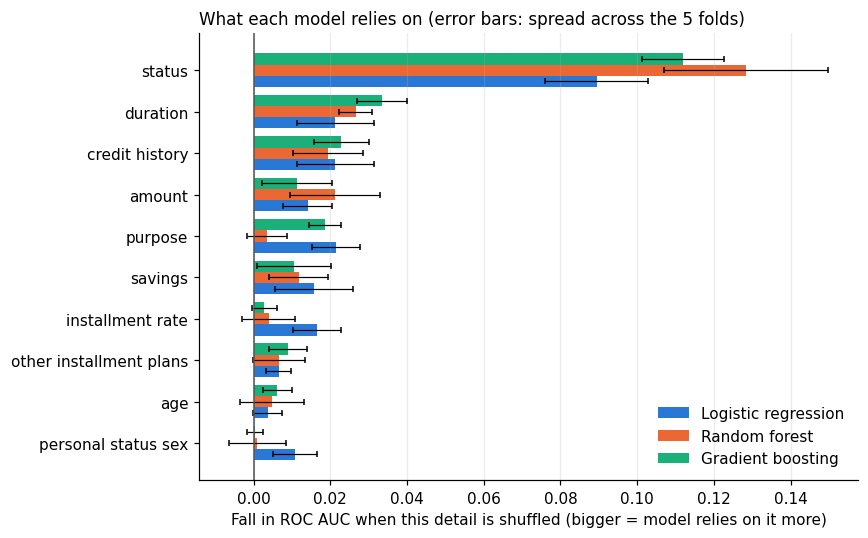

Rank agreement, Logistic regression vs Random forest: 0.81 (1 = identical ranking)
Rank agreement, Logistic regression vs Gradient boosting: 0.86 (1 = identical ranking)
Rank agreement, Random forest vs Gradient boosting: 0.93 (1 = identical ranking)
Logistic regression, top 5 (folds where it stays in the top 5): status (5/5), purpose (3/5), credit history (3/5), duration (4/5), installment rate (3/5)
Random forest, top 5 (folds where it stays in the top 5): status (5/5), duration (5/5), amount (4/5), credit history (4/5), savings (3/5)
Gradient boosting, top 5 (folds where it stays in the top 5): status (5/5), duration (5/5), credit history (5/5), purpose (5/5), amount (1/5)

Age's own importance for Logistic regression: AUC drop 0.004, rank 11 of 20.
Combinations of details: the tree models can learn them, logistic regression can't. Best tree ROC AUC 0.777 vs logistic regression 0.787: the trees gain nothing from them on this data.


In [27]:
# Permutation importance for all three models, on each model's own held-out fold
perm = {}
for name, models in FOLD_MODELS.items():
    per_fold = []
    for m, te in zip(models, TEST_FOLDS):
        r = permutation_importance(m, X.iloc[te], y.iloc[te], scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1)
        per_fold.append(pd.Series(r.importances_mean, index=X.columns))
    perm[name] = pd.DataFrame(per_fold)
    print(f"{name}: permutation importance done", flush=True)
perm_mean = pd.DataFrame({n: d.mean() for n, d in perm.items()})
perm_sd = pd.DataFrame({n: d.std() for n, d in perm.items()})
perm_rank = perm_mean.rank(ascending=False).astype(int)
order = perm_mean.mean(1).sort_values(ascending=False).index

imp_table = pd.DataFrame(index=order)
for n in perm_mean:
    short = {"Logistic regression": "LR", "Random forest": "RF", "Gradient boosting": "GB"}[n]
    imp_table[f"{short}: AUC drop"] = perm_mean.loc[order, n]
    imp_table[f"{short}: fold sd"] = perm_sd.loc[order, n]
    imp_table[f"{short}: rank"] = perm_rank.loc[order, n]
imp_table.index = imp_table.index.str.replace("_", " ")
display(imp_table.head(12).style.format({c: "{:.3f}" for c in imp_table.columns if "rank" not in c}))

fig, ax = plt.subplots(figsize=(8, 5))
top10 = order[:10][::-1]
for j, n in enumerate(perm_mean):
    ax.barh(np.arange(10) + (j - 1) * 0.27, perm_mean.loc[top10, n], height=0.27, xerr=perm_sd.loc[top10, n],
            color=MODEL_COLOURS[n], label=n, error_kw={"lw": 0.8, "capsize": 2})
ax.set_yticks(range(10)); ax.set_yticklabels(top10.str.replace("_", " "))
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("Fall in ROC AUC when this detail is shuffled (bigger = model relies on it more)")
ax.set_title("What each model relies on (error bars: spread across the 5 folds)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

names = list(perm_mean)
for i in range(3):
    for j in range(i + 1, 3):
        rho = spearmanr(perm_mean[names[i]], perm_mean[names[j]]).correlation
        print(f"Rank agreement, {names[i]} vs {names[j]}: {rho:.2f} (1 = identical ranking)")
for n in names:
    top5 = perm_mean[n].sort_values(ascending=False).index[:5]
    in_top5 = {f: int((perm[n].rank(axis=1, ascending=False)[f] <= 5).sum()) for f in top5}
    print(f"{n}, top 5 (folds where it stays in the top 5): " + ", ".join(f"{f.replace('_', ' ')} ({k}/5)" for f, k in in_top5.items()))
print(f"\nAge's own importance for {BEST}: AUC drop {perm_mean.loc['age', BEST]:.3f}, rank {perm_rank.loc['age', BEST]} of {len(order)}.")
best_auc = max(results.loc[n, "AUC"] for n in oof)
tree_auc = max(results.loc[n, "AUC"] for n in ["Random forest", "Gradient boosting"])
print(f"Combinations of details: the tree models can learn them, logistic regression can't. Best tree ROC AUC {tree_auc:.3f} vs "
      f"logistic regression {results.loc['Logistic regression', 'AUC']:.3f}: "
      + ("the trees gain nothing from them on this data." if tree_auc <= results.loc["Logistic regression", "AUC"]
         else "the trees rank slightly better, so some combinations may help."))

**How to read this.** A detail near the top for all three models, with a small fold spread, is something the data really supports. A detail that moves up and down between folds, or matters to one model only, is weak evidence. Permutation importance near 0 means the model would do just as well without that detail, though it may share information with another one (warning 2 above).

**What it can't tell us:** whether a detail is *fair* to use (section 3.1), or whether it *causes* repayment.

### 3.3 One applicant, step by step (hypothetical)
**Question:** how does the model turn someone's details into a yes or a no?

This is a **made-up applicant**, not a real person: age 30, 4 to 7 years in their job, 100 to 500 DM in savings, existing credits paid back on time so far, borrowing 2,500 DM over 24 months. Every other detail is set to the most common value in the data.

Logistic regression starts from the score of a perfectly **average applicant**, then adds or subtracts one amount per detail, depending on how this person differs from average. The total becomes a probability. Positive pieces push towards "lend" and negative ones towards "don't lend".

,this applicant,effect on score (log-odds),pushes towards
telephone,no,-0.099,don't lend
duration,24,-0.081,don't lend
age,30,-0.073,don't lend
credit history,existing credits paid duly so far,-0.053,don't lend
foreign worker,no,-0.020,don't lend
other debtors,none,-0.019,don't lend
property,building society savings / life insurance,-0.016,don't lend
job,skilled,-0.011,don't lend
installment rate,3 (band 3 of 4),-0.007,don't lend
present residence,3 (4-7 years),-0.001,don't lend


HYPOTHETICAL applicant (made up, not a real person)
  Average applicant's score: +1.10  (75.1%)
  Sum of this applicant's pieces: +1.61
  Final score +2.71 -> chance of repaying 93.8%   (model's own answer: 93.8%)
  Cut-off 83.3% -> LEND
  Biggest push towards lending: status (+0.71); biggest push against: telephone (-0.10)
  Remember: the model learned from data with 30% bad loans, so every probability here is lower than a real bank's would be (section 2.6).


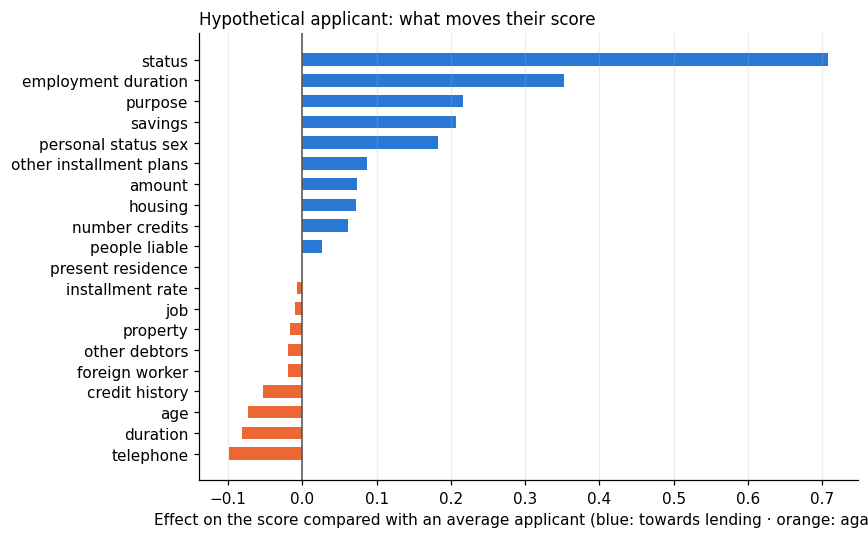

In [28]:
sigmoid = lambda s: 1 / (1 + np.exp(-s))
HYPO = {c: X[c].mode()[0] for c in CAT} | {c: int(X[c].median()) for c in NUM}
HYPO |= {"age": 30, "employment_duration": "4-7 years", "savings": "100-500 DM",
         "credit_history": "existing credits paid duly so far", "amount": 2500, "duration": 24}

def breakdown(applicant):
    """Start from the average applicant's score, then one piece per detail (logistic regression from section 3)."""
    z = prep.transform(pd.DataFrame([applicant])[COLS])[0]
    pieces = pd.Series(lr.coef_[0] * (z - Z.mean(0)), index=col_names)
    pieces = pieces.groupby([original_feature(n) for n in col_names]).sum()
    return lr.intercept_[0] + Z.mean(0) @ lr.coef_[0], pieces

base, pieces = breakdown(HYPO)
total = base + pieces.sum()
walk = pd.DataFrame({"this applicant": [show_value(f, HYPO[f]) for f in pieces.index], "effect on score (log-odds)": pieces.values},
                    index=pieces.index.str.replace("_", " ")).sort_values("effect on score (log-odds)")
walk["pushes towards"] = np.where(walk["effect on score (log-odds)"] > 0, "lend", "don't lend")
display(walk.style.format({"effect on score (log-odds)": "{:+.3f}"}))

print(f"HYPOTHETICAL applicant (made up, not a real person)")
print(f"  Average applicant's score: {base:+.2f}  ({sigmoid(base):.1%})")
print(f"  Sum of this applicant's pieces: {pieces.sum():+.2f}")
print(f"  Final score {total:+.2f} -> chance of repaying {sigmoid(total):.1%}   (model's own answer: {p_good(pd.DataFrame([HYPO]))[0]:.1%})")
verdict_txt = "LEND" if sigmoid(total) > THRESHOLD else "DON'T LEND"
print(f"  Cut-off {THRESHOLD:.1%} -> {verdict_txt}")
print(f"  Biggest push towards lending: {walk.index[-1]} ({walk.iloc[-1, 1]:+.2f}); biggest push against: {walk.index[0]} ({walk.iloc[0, 1]:+.2f})")
print("  Remember: the model learned from data with 30% bad loans, so every probability here is lower than a real bank's would be (section 2.6).")

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(walk.index, walk["effect on score (log-odds)"], color=[BLUE if v > 0 else ORANGE for v in walk["effect on score (log-odds)"]], height=0.6)
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("Effect on the score compared with an average applicant (blue: towards lending · orange: against)")
ax.set_title("Hypothetical applicant: what moves their score", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## 4. Proxy test: if we delete age, does the bias go away?

**Question:** if the model can't see age, does the gap go away? The obvious fix is "just don't let the model see age". This is called **fairness through unawareness**. We test whether it works.

In [29]:
NUM_NOAGE = [c for c in NUM if c != "age"]
X_noage = X.drop(columns="age")

def fairness_row(p, label, t=THRESHOLD):
    a = p > t
    ev = evaluate(y, a)
    gm_, pt_, ci_ = fairness_summary(a)
    return {"option": label, "accuracy": ev["accuracy"], "cost": ev["cost"],
            "approved, under 25": gm_.loc["Under 25", "approval rate"],
            "approved, 25+": gm_.loc["25 or older", "approval rate"],
            "gap (points)": pt_["approval gap"] * 100,
            "gap 95% CI": f"{ci_['approval gap'][0] * 100:.0f} to {ci_['approval gap'][1] * 100:.0f}",
            "ratio": pt_["approval ratio (young / older)"],
            "good-risk gap (points)": pt_["good-risk approval gap"] * 100}

FMT = {"good-risk gap (points)": "{:.1f}", "accuracy": "{:.1%}", "cost": "{:,.0f}", "approved, under 25": "{:.1%}", "approved, 25+": "{:.1%}",
       "gap (points)": "{:.1f}", "ratio": "{:.2f}"}

pipe, grid = make_models(CAT, NUM_NOAGE)["Logistic regression"]
p_noage, _, _ = out_of_fold_probs(pipe, grid, X_noage, y)
options = [fairness_row(oof["Logistic regression"], "Original (sees age)"),
           fairness_row(p_noage, "Age deleted")]
pd.DataFrame(options).set_index("option").style.format(FMT)

,accuracy,cost,"approved, under 25","approved, 25+",gap (points),gap 95% CI,ratio,good-risk gap (points)
option,,,,,,,,
Original (sees age),58.5%,547,18.8%,38.0%,19.2,12 to 26,0.50,19.5
Age deleted,58.5%,539,19.5%,37.4%,17.9,11 to 25,0.52,17.8


### 4.1 Which details give age away?
If the other details can **predict** whether someone is under 25, the model can still "see" age indirectly. These details are called **proxies**.

We train a model to predict *"is this person under 25?"* using everything except age. Then we test each detail on its own.

**How to read AUC:** 0.5 means no better than guessing, 1.0 means perfect.

All details together predict 'under 25' with AUC 0.80



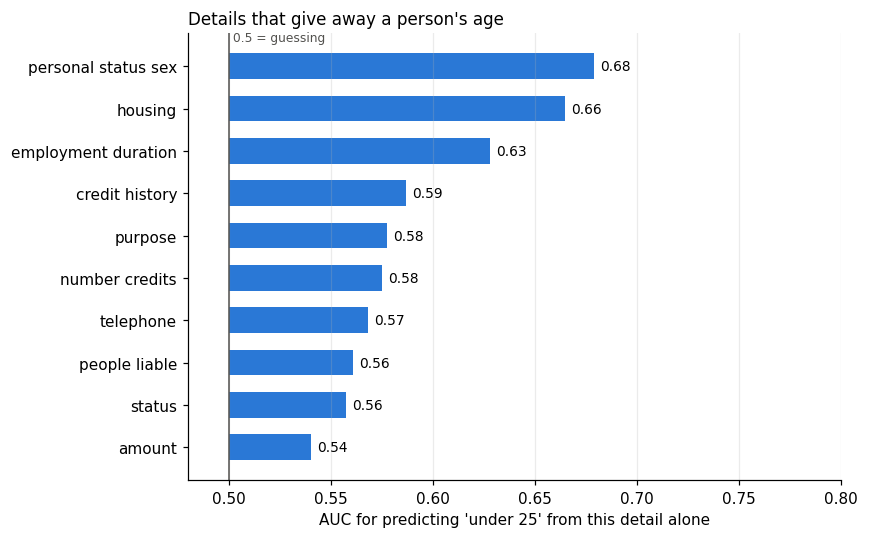

Top 3 proxies: ['personal_status_sex', 'housing', 'employment_duration']


In [30]:
from sklearn.model_selection import cross_val_predict
y_young = pd.Series(young.astype(int), name="under_25")

pipe, grid = make_models(CAT, NUM_NOAGE)["Logistic regression"]
p_young, _, _ = out_of_fold_probs(pipe, grid, X_noage, y_young)
print(f"All details together predict 'under 25' with AUC {roc_auc_score(y_young, p_young):.2f}\n")

single = {}
for f in X_noage.columns:
    cat_f, num_f = ([f], []) if f in CAT else ([], [f])
    one = Pipeline([("prep", make_preprocessor(cat_f, num_f)), ("model", LogisticRegression(max_iter=5000))])
    single[f] = roc_auc_score(y_young, cross_val_predict(one, X_noage[[f]], y_young, cv=OUTER, method="predict_proba")[:, 1])
proxy_auc = pd.Series(single).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
top_p = proxy_auc[-10:]
ax.barh(top_p.index.str.replace("_", " "), top_p.values - 0.5, left=0.5, color=BLUE, height=0.6)
for i, v in enumerate(top_p.values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=9)
ax.axvline(0.5, color="#52514e", lw=1); ax.text(0.502, len(top_p) - 0.4, "0.5 = guessing", fontsize=8, color="#52514e")
ax.set_xlim(0.48, max(0.8, top_p.max() + 0.05))
ax.set_xlabel("AUC for predicting 'under 25' from this detail alone")
ax.set_title("Details that give away a person's age", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
TOP_PROXIES = proxy_auc.index[::-1][:3].tolist()
print("Top 3 proxies:", TOP_PROXIES)

### 4.2 What if we also delete the proxies?

In [31]:
X_noproxy = X_noage.drop(columns=TOP_PROXIES)
cat_np = [c for c in CAT if c not in TOP_PROXIES]
num_np = [c for c in NUM_NOAGE if c not in TOP_PROXIES]
pipe, grid = make_models(cat_np, num_np)["Logistic regression"]
p_noproxy, _, _ = out_of_fold_probs(pipe, grid, X_noproxy, y)
options.append(fairness_row(p_noproxy, f"Age + top 3 proxies deleted"))
pd.DataFrame(options).set_index("option").style.format(FMT)

,accuracy,cost,"approved, under 25","approved, 25+",gap (points),gap 95% CI,ratio,good-risk gap (points)
option,,,,,,,,
Original (sees age),58.5%,547,18.8%,38.0%,19.2,12 to 26,0.50,19.5
Age deleted,58.5%,539,19.5%,37.4%,17.9,11 to 25,0.52,17.8
Age + top 3 proxies deleted,57.2%,544,22.8%,34.8%,12.0,4 to 19,0.66,10.2


## 5. Fixing the gap, and what it costs

We try three different kinds of fix. All are judged on the same two things: **the gap** and **the cost** (5:1 rule).

| Fix | How it works | Uses age when deciding? |
|---|---|---|
| **Delete age / proxies** (section 4) | Hide the information | No |
| **Reweighing** | During training, give extra weight to under-represented combinations (young + good risk, older + bad risk) so "young = risky" is harder to learn as a shortcut | No |
| **Separate thresholds** | Keep the model, but let under-25s be approved at a slightly lower confidence | **Yes** |

The last fix is the most direct, but it treats people differently *because of* their age. Section 5.1 looks at whether a UK lender could actually use it.

In [32]:
# Reweighing (Kamiran & Calders): weight = P(group) x P(label) / P(group, label)
g = young.astype(int); yv = y.to_numpy()
w = np.ones(len(y))
for gi in (0, 1):
    for yi in (0, 1):
        m = (g == gi) & (yv == yi)
        w[m] = (g == gi).mean() * (yv == yi).mean() / m.mean()
print(pd.crosstab(np.where(young, "Under 25", "25 or older"), np.where(yv == 1, "good", "bad"),
                  values=w, aggfunc="first").round(2).rename_axis(index="weight given to", columns=None))

pipe, grid = make_models(CAT, NUM_NOAGE)["Logistic regression"]
p_reweigh, _, _ = out_of_fold_probs(pipe, grid, X_noage, y, sample_weight=w)
options.append(fairness_row(p_reweigh, "Age deleted + reweighing"))

                  bad  good
weight given to            
25 or older      1.07  0.97
Under 25         0.73  1.19


In [33]:
# Separate thresholds: older applicants keep 5/6; try every lower threshold for under-25s
p_lr = oof["Logistic regression"]
sweep = []
for t_y in np.linspace(0.40, THRESHOLD, 90):
    a = np.where(young, p_lr > t_y, p_lr > THRESHOLD)
    r_y, r_o = a[young].mean(), a[~young].mean()
    tpr_y, tpr_o = a[young & (yv == 1)].mean(), a[~young & (yv == 1)].mean()
    sweep.append({"t_young": t_y, "cost": evaluate(y, a)["cost"], "gap": (r_o - r_y) * 100,
                  "ratio": r_y / r_o, "tpr_gap": (tpr_o - tpr_y) * 100})
sweep = pd.DataFrame(sweep)

def threshold_option(rows, label):
    t_y = rows.sort_values("t_young").iloc[-1]["t_young"]    # strictest (cheapest) threshold that meets the target
    a = np.where(young, p_lr > t_y, p_lr > THRESHOLD)
    row = fairness_row(a.astype(float), f"{label} (under-25 threshold {t_y:.2f})", t=0.5)
    return row

options.append(threshold_option(sweep[sweep["ratio"] >= 0.8], "Separate threshold: ratio 0.8"))
options.append(threshold_option(sweep[sweep["tpr_gap"] <= 0], "Separate threshold: equal chance for good risks"))
options.append(threshold_option(sweep[sweep["gap"] <= 0], "Separate threshold: equal approval rates"))
# The same fix with the under-25 cut-off chosen OUT OF FOLD: for each test fold, the cut-off is picked
# using only the other four folds, so the test predictions never influence it.
def pick_t_young(mask):
    best = 0.40
    for t_y in np.linspace(0.40, THRESHOLD, 90):
        a = np.where(young, p_lr > t_y, p_lr > THRESHOLD)[mask]
        g_ = young[mask]
        if a[g_].mean() / a[~g_].mean() >= 0.8:
            best = t_y                                   # keep the strictest cut-off that still reaches 0.8
    return best
a_fix_oof = np.zeros(len(yv), bool)
T_OOF = []
for k in range(5):
    t_k = pick_t_young(FOLDS != k); T_OOF.append(round(float(t_k), 2))
    te = FOLDS == k
    a_fix_oof[te] = np.where(young[te], p_lr[te] > t_k, p_lr[te] > THRESHOLD)
options.append(fairness_row(a_fix_oof.astype(float), "Separate threshold: ratio 0.8, chosen out of fold", t=0.5))
print("Under-25 cut-offs chosen out of fold, one per test fold:", T_OOF)
fixes = pd.DataFrame(options).set_index("option")
base_cost = fixes.loc["Original (sees age)", "cost"]
fixes["extra cost vs original"] = (fixes["cost"] / base_cost - 1)
fixes.style.format(FMT | {"extra cost vs original": "{:+.1%}"})

Under-25 cut-offs chosen out of fold, one per test fold: [0.75, 0.77, 0.79, 0.74, 0.75]


,accuracy,cost,"approved, under 25","approved, 25+",gap (points),gap 95% CI,ratio,good-risk gap (points),extra cost vs original
option,,,,,,,,,
Original (sees age),58.5%,547,18.8%,38.0%,19.2,12 to 26,0.50,19.5,+0.0%
Age deleted,58.5%,539,19.5%,37.4%,17.9,11 to 25,0.52,17.8,-1.5%
Age + top 3 proxies deleted,57.2%,544,22.8%,34.8%,12.0,4 to 19,0.66,10.2,-0.5%
Age deleted + reweighing,58.6%,538,22.1%,37.0%,14.9,7 to 23,0.60,12.8,-1.6%
Separate threshold: ratio 0.8 (under-25 threshold 0.76),59.9%,541,30.9%,38.0%,7.1,-1 to 16,0.81,1.3,-1.1%
Separate threshold: equal chance for good risks (under-25 threshold 0.74),60.1%,543,33.6%,38.0%,4.4,-4 to 13,0.88,-2.1,-0.7%
Separate threshold: equal approval rates (under-25 threshold 0.72),60.2%,554,38.3%,38.0%,-0.3,-9 to 8,1.01,-6.7,+1.3%
"Separate threshold: ratio 0.8, chosen out of fold",59.7%,547,30.9%,38.0%,7.1,-1 to 16,0.81,2.4,+0.0%


**Chart: the price of fairness.** Each dot is one option. Further left = fairer, lower = cheaper. The line shows every possible separate threshold for under-25s.

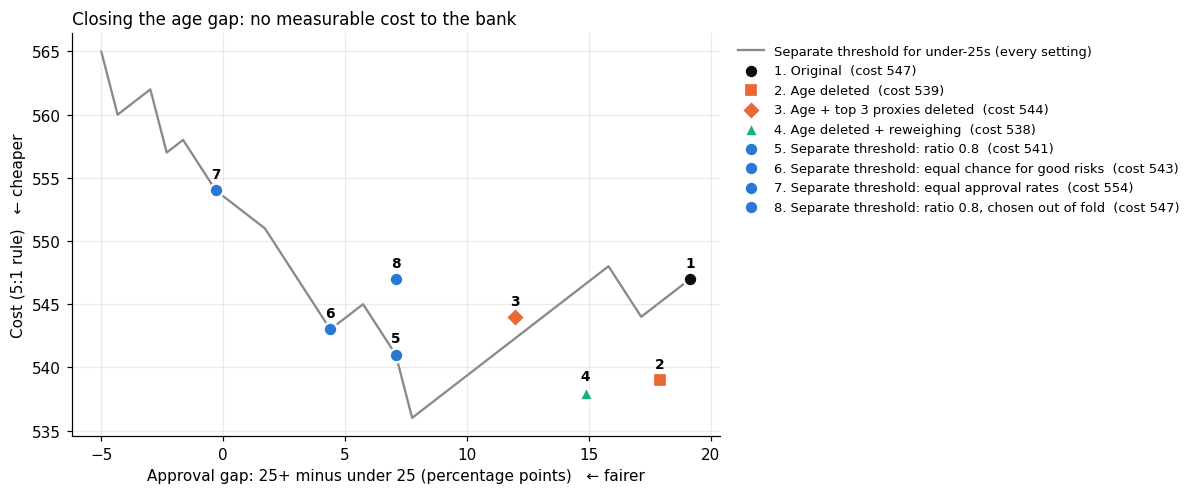

In [34]:
fig, ax = plt.subplots(figsize=(11, 4.6))
near = sweep[sweep["gap"] >= -6]
ax.plot(near["gap"], near["cost"], color=GREY, lw=1.5, zorder=1, label="Separate threshold for under-25s (every setting)")
styles = {"Original": ("#0b0b0b", "o"), "Age deleted + reweighing": ("#1baf7a", "^"),
          "Age deleted": (ORANGE, "s"), "Age +": (ORANGE, "D"), "Separate": (BLUE, "o")}
for n, (opt, r) in enumerate(fixes.iterrows(), start=1):
    colour, mk = next(v for k, v in styles.items() if opt.startswith(k))
    ax.scatter(r["gap (points)"], r["cost"], s=80, color=colour, marker=mk, zorder=3, edgecolor="white", linewidth=1.5,
               label=f"{n}. {opt.split(' (')[0]}  (cost {r['cost']:,.0f})")
    ax.annotate(str(n), (r["gap (points)"], r["cost"]), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, weight="bold")
ax.set_xlabel("Approval gap: 25+ minus under 25 (percentage points)   ← fairer")
ax.set_ylabel("Cost (5:1 rule)   ← cheaper")
ax.set_title("Closing the age gap: no measurable cost to the bank", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8.5)
plt.tight_layout(); plt.show()

In [35]:
o = fixes.loc["Original (sees age)"]
print("PRICE OF FAIRNESS (compared with the original model)\n")
for opt, r in fixes.iterrows():
    if opt == "Original (sees age)":
        continue
    print(f"{opt}")
    print(f"   gap {o['gap (points)']:.1f} -> {r['gap (points)']:.1f} points, "
          f"ratio {o['ratio']:.2f} -> {r['ratio']:.2f}, cost {o['cost']:,.0f} -> {r['cost']:,.0f} ({r['extra cost vs original']:+.1%})")

PRICE OF FAIRNESS (compared with the original model)

Age deleted
   gap 19.2 -> 17.9 points, ratio 0.50 -> 0.52, cost 547 -> 539 (-1.5%)
Age + top 3 proxies deleted
   gap 19.2 -> 12.0 points, ratio 0.50 -> 0.66, cost 547 -> 544 (-0.5%)
Age deleted + reweighing
   gap 19.2 -> 14.9 points, ratio 0.50 -> 0.60, cost 547 -> 538 (-1.6%)
Separate threshold: ratio 0.8 (under-25 threshold 0.76)
   gap 19.2 -> 7.1 points, ratio 0.50 -> 0.81, cost 547 -> 541 (-1.1%)
Separate threshold: equal chance for good risks (under-25 threshold 0.74)
   gap 19.2 -> 4.4 points, ratio 0.50 -> 0.88, cost 547 -> 543 (-0.7%)
Separate threshold: equal approval rates (under-25 threshold 0.72)
   gap 19.2 -> -0.3 points, ratio 0.50 -> 1.01, cost 547 -> 554 (+1.3%)
Separate threshold: ratio 0.8, chosen out of fold
   gap 19.2 -> 7.1 points, ratio 0.50 -> 0.81, cost 547 -> 547 (+0.0%)


**How to read this:** the honest comparison is the out-of-fold version of the separate threshold, because its cut-off never saw the test data. The next cell checks whether its cost differs from the original by more than chance, and who the extra approvals actually are.

**Caveat for honesty:** the three separate-threshold rows above it chose their cut-off on the same out-of-sample predictions we then score them on, so their cost (541 to 554) is slightly optimistic. The out-of-fold row removes that problem and is the one we quote. With more time we would go one step further and choose the cut-off with a full inner cross-validation inside each training fold.

In [36]:
# Paired bootstrap: resample applicants, compare the fix and the original on the SAME resample each time
a_orig = p_lr > THRESHOLD
boot = np.random.default_rng(SEED).integers(0, len(yv), size=(2000, len(yv)))
def boot_cost(a):
    A, Y = a[boot], yv[boot]
    return 5 * ((Y == 0) & A).sum(1) + ((Y == 1) & ~A).sum(1)
diff = boot_cost(a_fix_oof) - boot_cost(a_orig)
lo, hi = np.percentile(diff, [2.5, 97.5])
print(f"Cost: original {evaluate(y, a_orig)['cost']}, fix (out of fold) {evaluate(y, a_fix_oof)['cost']}")
print(f"Cost difference (fix minus original), 95% interval: {lo:+.0f} to {hi:+.0f}  ->  no measurable change in cost" if lo < 0 < hi
      else f"Cost difference 95% interval: {lo:+.0f} to {hi:+.0f}")

extra = a_fix_oof & ~a_orig & young
print(f"\nWho the fix adds: {extra.sum()} extra under-25 approvals, of whom {int(yv[extra].sum())} actually repaid "
      f"and {int((1 - yv[extra]).sum())} did not.")
gm_f, pt_f, ci_f = fairness_summary(a_fix_oof)
print(f"Main measure (approved among good risks): gap {point['good-risk approval gap'] * 100:.1f} -> {pt_f['good-risk approval gap'] * 100:.1f} points")

Cost: original 547, fix (out of fold) 547
Cost difference (fix minus original), 95% interval: -17 to +21  ->  no measurable change in cost

Who the fix adds: 18 extra under-25 approvals, of whom 15 actually repaid and 3 did not.
Main measure (approved among good risks): gap 19.5 -> 2.4 points


### 5.1 Which fix could a UK lender actually use?
**Question:** our strongest fix uses age directly. Is that a problem?

| Fix | Uses age when deciding? | What it shows |
|---|---|---|
| Age deleted + reweighing | No | Narrows the gap a little without treating anyone differently by age |
| Age + top 3 proxies deleted | No | Narrows it more, but throws away information the model uses |
| Separate cut-off for under-25s | **Yes** | Most of the gap is a cut-off effect, and closing it has no measurable net cost on this data |

**The legal picture (not legal advice).** The Equality Act 2010 has an exception for financial services (Schedule 3, paragraph 20A): treating people differently by age *in connection with a financial service* is generally allowed, but where a lender's **risk assessment** takes age into account, it has to be based on information that is relevant to the risk and comes from a source it's reasonable to rely on. Our calibration check (6.3.1) shows young applicants' risk scores are already accurate, so a lower cut-off for them isn't a risk judgement. It is a decision about who to lend to. Whether that falls inside the exception is a question for a lawyer, not something this notebook can settle. Separately, the FCA's Consumer Duty expects firms to avoid causing foreseeable harm, and lending to more borderline applicants means some extra defaults (see the counts printed above).

**So we present it like this:** the age-blind fixes are what we'd recommend a lender test first. The separate cut-off is a measurement: it shows how much of the gap comes from where the bar sits, and what closing it would cost. Section 6.3.3 shows its side effect on 25 to 29 year olds.

**"No extra cost" means net cost.** On the 5:1 scale, the extra defaults are cancelled out by the extra good customers served. The bank still lends more money and loses more to defaults in money terms (section 7.3). It's the *balance* that doesn't change.

## 6. Flip test, and an audit of the data itself

### 6.1 Flip test: change only the age
Take each applicant, change **nothing except their age**, and ask the model again. If decisions change, age itself is driving them.

We use the logistic regression trained on all 1,000 applicants (section 3).

In [37]:
p_now = p_good(X)
X_35 = X.copy(); X_35.loc[young, "age"] = 35          # every under-25 becomes 35
X_22 = X.copy(); X_22.loc[~young, "age"] = 22         # every 25+ becomes 22
p_as35, p_as22 = p_good(X_35), p_good(X_22)

app_now = p_now > THRESHOLD
gained = (~app_now & (p_as35 > THRESHOLD))[young]
lost = (app_now & (p_as22 <= THRESHOLD))[~young]
print(f"Under-25s rejected now but approved if they were 35: {gained.sum()} of {young.sum()} "
      f"({gained.mean():.0%})")
print(f"25+ approved now but rejected if they were 22:       {lost.sum()} of {(~young).sum()} "
      f"({lost.mean():.0%})")
print(f"\nAverage change in approval chance for under-25s made 35: {100 * (p_as35 - p_now)[young].mean():+.1f} points")
flipped_young = np.where(young & ~app_now & (p_as35 > THRESHOLD))[0]
EX_IDX = flipped_young[0] if len(flipped_young) else int(np.where(young)[0][np.argmax(p_now[young])])

Under-25s rejected now but approved if they were 35: 2 of 149 (1%)
25+ approved now but rejected if they were 22:       45 of 851 (5%)

Average change in approval chance for under-25s made 35: +3.1 points


**Chart: approval chance by age for one real young applicant** (one whose decision flips). All their details stay fixed; only age changes. The fairer model from section 5 (age deleted, reweighed) is shown for comparison.

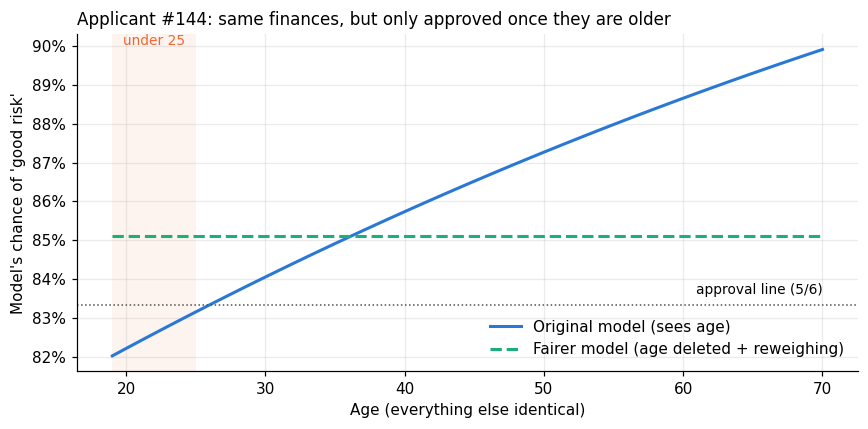

Applicant #144 is really 23; the original model would first approve them at age 26


In [38]:
fair_pipe, fair_grid = make_models(CAT, NUM_NOAGE)["Logistic regression"]
fair_full = GridSearchCV(fair_pipe, fair_grid, cv=INNER, scoring="neg_log_loss").fit(
    X_noage, y, model__sample_weight=w).best_estimator_

typical = {c: X[c].mode()[0] for c in CAT} | {c: int(X[c].median()) for c in NUM}
ages = np.arange(19, 71)
person = X.iloc[EX_IDX].to_dict()
curve = pd.DataFrame([person | {"age": a} for a in ages])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ages, p_good(curve), color=BLUE, lw=2, label="Original model (sees age)")
ax.plot(ages, fair_full.predict_proba(curve.drop(columns="age"))[:, 1], color="#1baf7a", lw=2, ls="--",
        label="Fairer model (age deleted + reweighing)")
ax.axhline(THRESHOLD, color="#52514e", lw=1, ls=":"); ax.text(70, THRESHOLD + 0.002, "approval line (5/6)", ha="right", va="bottom", fontsize=9)
ax.axvspan(19, 25, color=ORANGE, alpha=0.08, lw=0)
ax.text(22, ax.get_ylim()[1], "under 25", color=ORANGE, fontsize=9, ha="center", va="top")
ax.set_xlabel("Age (everything else identical)"); ax.set_ylabel("Model's chance of 'good risk'")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title(f"Applicant #{EX_IDX}: same finances, but only approved once they are older", loc="left", fontsize=11)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
cross = ages[p_good(curve) > THRESHOLD]
print(f"Applicant #{EX_IDX} is really {person['age']}; the original model would first approve them at age {cross.min() if len(cross) else 'never'}")

**Important limitation of the flip test:** it only catches age's *direct* effect. Section 3 showed most of the gap comes *through* details linked to age (housing, job length, family status and so on). A model with age deleted would pass the flip test perfectly and still have a large gap (section 4). So passing a flip test does **not** prove a model is fair.

One more thing to notice: logistic regression treats age as a straight line, so it assumes "older is always safer". In reality, risk may rise again for the very old. A curved age effect would be a good extension.

### 6.2 Questioning the data
Before trusting any fairness result, we checked the data itself. Several problems are documented in a corrected version of the dataset (*South German Credit*, Grömping 2019, on the UCI repository):

In [39]:
audit = pd.DataFrame([
    {"issue": "Sex cannot be recovered",
     "evidence in our data": "family status codes: " + ", ".join(f"{k} = {v}" for k, v in X['personal_status_sex'].value_counts().items()),
     "why it matters": "One code mixes women who are not single with single men, so any 'women' analysis is meaningless. Many published fairness studies used it anyway."},
    {"issue": "The Statlog codebook mislabels categories (fixed)",
     "evidence in our data": "codes matched to the corrected South German Credit data in section 1.1b",
     "why it matters": "With the old labels, 'no checking account' looked like the strongest sign of a good borrower and 'renting' looked like a sign of youth. "
                       "Those codes really mean '200 DM or more, or a salary account' and 'lives for free'. Explanations built on the old labels would be wrong, "
                       "even though the numbers are not affected. We use the corrected labels throughout."},
    {"issue": "Some 'numbers' are really ordered categories",
     "evidence in our data": "installment rate, years at address, number of credits and people supported only take values 1 to 4",
     "why it matters": "The model treats them as evenly spaced steps, which they may not be."},
    {"issue": "Installment rate's meaning is disputed",
     "evidence in our data": "repaid: " + ", ".join(f"band {k} {v:.0%}" for k, v in pd.Series(yv).groupby(X['installment_rate'].to_numpy()).mean().items()),
     "why it matters": "Statlog says band 4 is the heaviest repayment burden; the corrected codebook says it is the lightest. Band 4 repaid least, which fits Statlog better. "
                       "So we use this detail for prediction but don't claim which way the burden runs."},
    {"issue": "Bad loans heavily oversampled",
     "evidence in our data": f"{(1 - yv.mean()):.0%} bad in the data",
     "why it matters": "The real share of bad loans is reported to be only about 5% (Grömping 2019, relaying the original German sources), so costs and default chances are inflated, and approval rates are too low, compared with a real bank (section 2.6)."},
    {"issue": "Old data",
     "evidence in our data": "loans from 1973–75",
     "why it matters": "Lending, jobs and housing for young people have changed a lot since then."},
    {"issue": "Labels are real outcomes, but only for people who got loans",
     "evidence in our data": "all 1,000 rows are granted credits; 'good' means the contract was repaid as agreed",
     "why it matters": "The label isn't a banker's opinion, it's what happened. But applicants the bank rejected never appear, so we can't see whether they would have repaid, and any past bias in who got a loan is baked into the data."},
]).set_index("issue")
audit.style.set_properties(**{"text-align": "left", "white-space": "normal"})

,evidence in our data,why it matters
issue,,
Sex cannot be recovered,"family status codes: male: married/widowed = 548, female (not single) or male (single) = 310, female: single = 92, male: divorced/separated = 50","One code mixes women who are not single with single men, so any 'women' analysis is meaningless. Many published fairness studies used it anyway."
The Statlog codebook mislabels categories (fixed),codes matched to the corrected South German Credit data in section 1.1b,"With the old labels, 'no checking account' looked like the strongest sign of a good borrower and 'renting' looked like a sign of youth. Those codes really mean '200 DM or more, or a salary account' and 'lives for free'. Explanations built on the old labels would be wrong, even though the numbers are not affected. We use the corrected labels throughout."
Some 'numbers' are really ordered categories,"installment rate, years at address, number of credits and people supported only take values 1 to 4","The model treats them as evenly spaced steps, which they may not be."
Installment rate's meaning is disputed,"repaid: band 1 75%, band 2 73%, band 3 71%, band 4 67%","Statlog says band 4 is the heaviest repayment burden; the corrected codebook says it is the lightest. Band 4 repaid least, which fits Statlog better. So we use this detail for prediction but don't claim which way the burden runs."
Bad loans heavily oversampled,30% bad in the data,"The real share of bad loans is reported to be only about 5% (Grömping 2019, relaying the original German sources), so costs and default chances are inflated, and approval rates are too low, compared with a real bank (section 2.6)."
Old data,loans from 1973–75,"Lending, jobs and housing for young people have changed a lot since then."
"Labels are real outcomes, but only for people who got loans","all 1,000 rows are granted credits; 'good' means the contract was repaid as agreed","The label isn't a banker's opinion, it's what happened. But applicants the bank rejected never appear, so we can't see whether they would have repaid, and any past bias in who got a loan is baked into the data."


### 6.3 Deeper fairness checks
Three extra checks on our main result. Each answers a question a sceptical judge would ask:

| Check | The question in plain English |
|---|---|
| **6.3.1 Calibration by age** | When the model says "83% sure", is that equally true for young and older applicants? |
| **6.3.2 Like for like** | If a young and an older applicant have similar finances, is there still a gap? |
| **6.3.3 Cliff edge** | Our fix draws a line at age 25. Is it fair to the 25-year-old just on the other side? |

Same rules as the rest of the notebook: every prediction is **out-of-fold** (made while that applicant was hidden from training), every interval comes from **2,000 bootstrap resamples** with a fixed seed, and nothing here is tuned on the test predictions. None of the earlier results change.

#### 6.3.1 Calibration by age: is "83% sure" equally true for both groups?
A model is **calibrated** if its confidence can be taken at face value: of the people it calls "80% likely to repay", about 80% really do. If the model were *underrating* young people, reliable young applicants would repay more often than it predicted. That would be a hidden unfairness inside the scores themselves.

We sort applicants into five confidence bands (set in advance; the top band is everyone above the 5/6 approval line) and compare what the model predicted with what actually happened, separately for each age group.

**How to read the chart:** dots on the dotted diagonal mean an honest model. Dots *above* it mean that group repaid more often than predicted (underrated); dots *below* mean overrated. The bars show the 95% interval, which is wide for under-25s because each band holds only 20 to 50 of them.

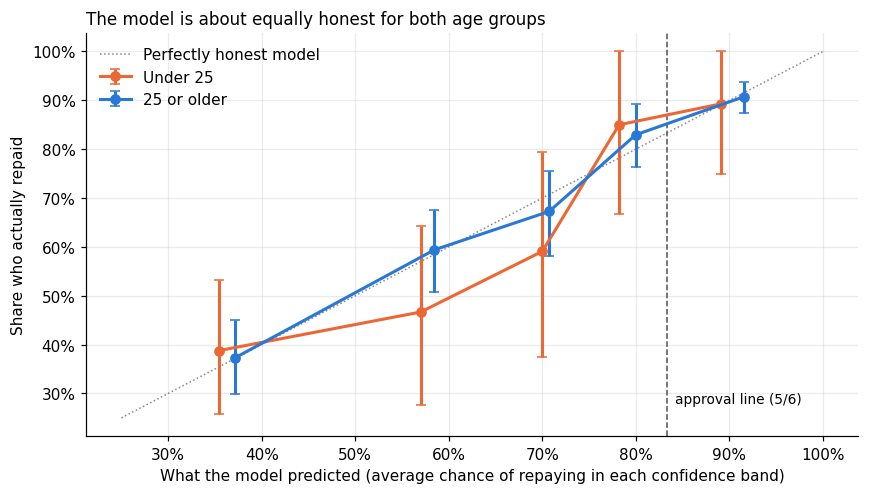

Actual repayment minus the model's prediction, in percentage points (95% interval):

  Everyone                       Under 25      -2.3  (-9.7 to +4.9)   no measurable difference from the prediction
  Everyone                       25 or older   +0.5  (-2.3 to +3.1)   no measurable difference from the prediction
                                 young - older  -2.7  (-10.5 to +4.9)

  Rejected (below the 5/6 line)  Under 25      -2.7  (-11.5 to +5.9)   no measurable difference from the prediction
  Rejected (below the 5/6 line)  25 or older   +0.9  (-3.0 to +4.7)   no measurable difference from the prediction
                                 young - older  -3.5  (-12.9 to +5.7)

  Just below the line (75–83%)   Under 25      +6.2  (-12.0 to +20.9)   no measurable difference from the prediction
  Just below the line (75–83%)   25 or older   +3.6  (-3.1 to +9.9)   no measurable difference from the prediction
                                 young - older  +2.6  (-16.2 to +18.3)

Just bel

In [40]:
# Calibration: when the model says "x% sure", how often did those people actually repay? Split by age group.
EDGES = [0, 0.50, 0.65, 0.75, THRESHOLD, 1.0]      # fixed in advance; 5/6 is an edge, so the last bin = approved
BIN_NAMES = ["under 50%", "50–65%", "65–75%", "75–83% (just below the line)", "above 83% (approved)"]
score_bin = np.digitize(p_lr, EDGES[1:-1], right=True)                              # which bin each applicant's score falls in
BOOT63 = np.random.default_rng(SEED).integers(0, len(yv), size=(2000, len(yv)))     # 2,000 resamples of the applicants
surprise = yv - p_lr                                 # +1 side: repaid more often than predicted (underrated)

def boot_mean(values, mask):
    """Average of `values` among the applicants in `mask`, with a 95% bootstrap interval."""
    M = mask[BOOT63]
    with np.errstate(invalid="ignore", divide="ignore"):
        b = (values[BOOT63] * M).sum(1) / M.sum(1)
    return values[mask].mean(), np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)

def boot_diff(values, mask_a, mask_b):
    """Difference in averages (group a minus group b), with a 95% bootstrap interval."""
    A, Bm = mask_a[BOOT63], mask_b[BOOT63]
    with np.errstate(invalid="ignore", divide="ignore"):
        b = (values[BOOT63] * A).sum(1) / A.sum(1) - (values[BOOT63] * Bm).sum(1) / Bm.sum(1)
    return values[mask_a].mean() - values[mask_b].mean(), np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)

AGE_GROUPS = [("Under 25", young, ORANGE), ("25 or older", ~young, BLUE)]
cal_rows, cal_points = [], {}
for label, grp, colour in AGE_GROUPS:
    pts = []
    for k, name in enumerate(BIN_NAMES):
        m63 = grp & (score_bin == k)
        act, a_lo, a_hi = boot_mean(yv.astype(float), m63)
        cal_rows.append({"group": label, "model's confidence": name, "people": int(m63.sum()),
                         "model predicted": p_lr[m63].mean(), "actually repaid": act,
                         "95% interval": f"{a_lo:.0%} to {a_hi:.0%}"})
        pts.append((p_lr[m63].mean(), act, a_lo, a_hi))
    cal_points[label] = pts
calibration = pd.DataFrame(cal_rows).set_index(["group", "model's confidence"])
display(calibration.style.format({"model predicted": "{:.1%}", "actually repaid": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot([0.25, 1], [0.25, 1], color=GREY, lw=1, ls=":", label="Perfectly honest model")
for (label, grp, colour), shift in zip(AGE_GROUPS, (-0.006, 0.006)):
    px, act, c_lo, c_hi = map(np.array, zip(*cal_points[label]))
    ax.errorbar(px + shift, act, yerr=[act - c_lo, c_hi - act], color=colour, marker="o", lw=2, capsize=3, label=label)
ax.axvline(THRESHOLD, color="#52514e", lw=1, ls="--"); ax.text(THRESHOLD + 0.008, 0.28, "approval line (5/6)", fontsize=9)
ax.set_xlabel("What the model predicted (average chance of repaying in each confidence band)")
ax.set_ylabel("Share who actually repaid")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("The model is about equally honest for both age groups", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

def reading(c_lo, c_hi):
    return ("UNDERRATED: repaid more often than predicted" if c_lo > 0 else
            "OVERRATED: repaid less often than predicted" if c_hi < 0 else "no measurable difference from the prediction")
print("Actual repayment minus the model's prediction, in percentage points (95% interval):\n")
for where, sel in [("Everyone", np.ones(len(yv), bool)), ("Rejected (below the 5/6 line)", score_bin < 4),
                   ("Just below the line (75–83%)", score_bin == 3)]:
    for label, grp, _ in AGE_GROUPS:
        d, d_lo, d_hi = boot_mean(surprise, grp & sel)
        print(f"  {where:30s} {label:12s} {100 * d:+5.1f}  ({100 * d_lo:+.1f} to {100 * d_hi:+.1f})   {reading(d_lo, d_hi)}")
    d, d_lo, d_hi = boot_diff(surprise, young & sel, ~young & sel)
    print(f"  {'':30s} {'young - older':12s} {100 * d:+5.1f}  ({100 * d_lo:+.1f} to {100 * d_hi:+.1f})\n")
band = score_bin == 3
print(f"Just below the line, {yv[young & band].mean():.0%} of under-25s ({int(yv[young & band].sum())} of {int((young & band).sum())}) and "
      f"{yv[~young & band].mean():.0%} of older applicants ({int(yv[~young & band].sum())} of {int((~young & band).sum())}) actually repaid. "
      f"The lending rule needs {THRESHOLD:.0%}.")

**What we found: no, the model does not underrate reliable young people.** Its confidence is about equally honest for both groups. Across all under-25s it predicted 61.3% would repay and 59.1% did (2.3 points fewer, 95% interval −9.7 to +4.9); for older applicants the difference is +0.5. No difference here is bigger than chance. The honest limit: with only 149 young applicants, a mismatch of up to about 10 points could hide in the noise.

This sharpens our story in two ways:
- The age gap is **not** caused by the model misjudging young people's risk. It comes from where the approval line falls: more young applicants sit just under it.
- Just under the line (scores of 75–83%), **both** groups did well: 85% of under-25s (17 of 20) and 83% of older applicants (107 of 129) repaid, which is right at the 83% the lending rule needs. These borderline applicants are about break-even for the bank whatever their age. That is why our fix costs nothing measurable, and it raises a question we answer in 6.3.3: what about the *older* borderline applicants?

#### 6.3.2 Like for like: is there still a gap between applicants with similar finances?
An obvious objection: "young people borrow differently and have less in the bank, so of course fewer are approved." This check compares like with like. It is the idea behind **conditional demographic disparity**, the measure recommended in the FCA's 2024 research note on bias: the gap between groups *after* allowing for legitimate differences.

We put every applicant into a group with the same checking-account status, the same savings band, and a similar loan amount and loan length (each split at the median). Inside each group we take the older approval rate minus the young approval rate, then average those gaps, giving more weight to groups with more young applicants. To check that our choices do not drive the answer, we repeat it with amount and length split into thirds.

**Honest caveat:** which details count as "legitimate" is a judgement, not a fact. We used the four details most clearly about the loan and the applicant's money, and left out life-stage details such as housing and job length (section 3.1).

In [41]:
# Like-for-like: compare young and older applicants only within groups that share the same finances
def finance_groups(n_bins):
    """Label each applicant by checking account, savings, loan-amount band and loan-length band."""
    amount_band = pd.qcut(X["amount"], n_bins, labels=False, duplicates="drop").astype(str)
    length_band = pd.qcut(X["duration"], n_bins, labels=False, duplicates="drop").astype(str)
    label = X["status"].astype(str) + " | " + X["savings"].astype(str) + " | amount " + amount_band + " | length " + length_band
    return pd.factorize(label)[0]

def like_for_like(approve, codes, good_only=False, idx=None):
    """Raw gap, and the gap after matching on finances: within each finance group, older approval rate minus young
    approval rate, averaged with weights = number of young applicants in the group. Both in percentage points."""
    idx = np.arange(len(yv)) if idx is None else idx
    keep = (yv[idx] == 1) if good_only else np.ones(len(idx), bool)
    c, yg, a = codes[idx], young[idx] & keep, approve[idx].astype(float)
    og = ~young[idx] & keep
    n_groups = codes.max() + 1
    n_y, n_o = np.bincount(c, yg, n_groups), np.bincount(c, og, n_groups)
    a_y, a_o = np.bincount(c, yg * a, n_groups), np.bincount(c, og * a, n_groups)
    both = (n_y > 0) & (n_o > 0)                                  # finance groups that contain both ages
    matched = (n_y[both] * (a_o[both] / n_o[both] - a_y[both] / n_y[both])).sum() / n_y[both].sum()
    raw = a_o.sum() / n_o.sum() - a_y.sum() / n_y.sum()
    return 100 * raw, 100 * matched, n_y[both].sum() / n_y.sum()

lfl_rows = []
for n_bins, detail in [(2, "main: amount and length split at the median"), (3, "check: amount and length split in thirds")]:
    codes = finance_groups(n_bins)
    for policy, approve in [("Original model (5/6)", a_orig), ("Our fix (cut-off chosen out of fold)", a_fix_oof)]:
        for measure, good_only in [("all applicants", False), ("good risks only (main measure)", True)]:
            raw, matched, covered = like_for_like(approve, codes, good_only)
            bs = np.array([like_for_like(approve, codes, good_only, i)[:2] for i in BOOT63])
            m_lo, m_hi = np.percentile(bs[:, 1], [2.5, 97.5])
            lfl_rows.append({"matching": detail, "policy": policy, "gap measured among": measure,
                             "raw gap (points)": raw, "like-for-like gap (points)": matched,
                             "95% interval": f"{m_lo:+.1f} to {m_hi:+.1f}",
                             "share of raw gap left": matched / raw if policy.startswith("Original") else np.nan,
                             "young applicants matched": covered})
lfl = pd.DataFrame(lfl_rows).set_index(["matching", "policy", "gap measured among"])
display(lfl.style.format({"raw gap (points)": "{:+.1f}", "like-for-like gap (points)": "{:+.1f}",
                          "share of raw gap left": "{:.0%}", "young applicants matched": "{:.0%}"}, na_rep="–"))

main = lfl.loc["main: amount and length split at the median"]
o_all, o_good = main.loc[("Original model (5/6)", "all applicants")], main.loc[("Original model (5/6)", "good risks only (main measure)")]
f_all = main.loc[("Our fix (cut-off chosen out of fold)", "all applicants")]
print(f"{finance_groups(2).max() + 1} finance groups. Original model: approval gap {o_all['raw gap (points)']:.1f} points -> "
      f"{o_all['like-for-like gap (points)']:.1f} like for like ({o_all['95% interval']}), so {o_all['share of raw gap left']:.0%} of the gap "
      f"remains between applicants with similar finances.")
print(f"Good risks only: {o_good['raw gap (points)']:.1f} -> {o_good['like-for-like gap (points)']:.1f} points ({o_good['95% interval']}).")
print(f"After our fix, the like-for-like approval gap is {f_all['like-for-like gap (points)']:+.1f} points ({f_all['95% interval']}).")

72 finance groups. Original model: approval gap 19.2 points -> 11.3 like for like (+5.1 to +17.8), so 59% of the gap remains between applicants with similar finances.
Good risks only: 19.5 -> 13.6 points (+4.7 to +23.3).
After our fix, the like-for-like approval gap is -0.8 points (-8.2 to +6.6).


**What we found: most of the gap survives.** Between applicants with similar finances, the approval gap is still **11.3 points** (95% interval 5.1 to 17.8), which is **59% of the raw 19.2-point gap**. So roughly 40% of the gap is explained by young people's different finances, and roughly 60% is not. On our main measure (good risks only), 13.6 of the 19.5 points remain (4.7 to 23.3).

The finer split gives a similar answer (10.0 points remain), but for good risks only its interval just touches zero (−0.5 to +19.0), because the groups become very small. So the safe statement is "about half or more of the gap remains like for like", not an exact share.

**After our fix, the like-for-like gap disappears:** −0.8 points (−8.2 to +6.6). Young and older applicants with similar finances are then approved at the same rate, within noise.

#### 6.3.3 Cliff edge: is the fix fair to the 25-year-old next door?
Our fix lowers the approval line for under-25s only. Any rule with an age line creates a cliff: a 24-year-old and a 26-year-old with the *same score* can now get different answers, this time in the young person's favour. A strict judge will ask about this, so we measure it.

- **Leapfrogged** applicants are people aged 25 or older who are still rejected, although their score would now get an under-25 approved.
- We also look at how often good risks are approved in each age band, before and after the fix, to see who is worst off afterwards.
- Finally we test the age-blind alternative: give **everyone** the lower line. It is the same out-of-fold line as in section 5 (chosen so young applicants reach a 0.8 ratio), so it was never tuned on cost or on these results.

,good risks in band,approved before fix,approved after fix,after: 95% interval,leapfrogged,of whom repaid
age band,,,,,,
Under 25,88,28.4%,45.5%,35% to 56%,0,0
25–29,146,34.9%,34.9%,27% to 43%,33,28
30–39,245,49.4%,49.4%,43% to 56%,47,40
40–59,183,55.2%,55.2%,48% to 62%,34,32
60 or older,38,52.6%,52.6%,36% to 69%,8,6


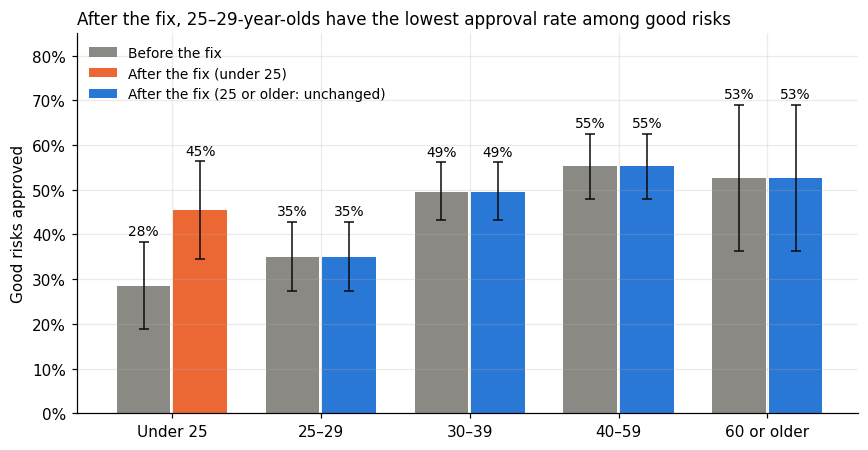

The fix approves 18 extra under-25s, of whom 15 repaid (83%).
It leaves 122 applicants aged 25+ rejected with scores that would get an under-25 approved; 106 of them repaid (87%).
Good risks approved after the fix: 25–29 minus under 25 = -10.5 points (95% interval -23.2 to +3.2)  ->  within noise.


,cost,"cost vs original, 95% interval",approved,good-risk gap (points),gap 95% interval,ratio (young / older),people leapfrogged
policy,,,,,,,
Original: 5/6 for everyone,547,–,35.1%,+19.5,+9 to +30,0.50,0
Our fix: lower cut-off for under-25s only,547,-17 to +21,36.9%,+2.4,-9 to +14,0.81,122
Age-blind: the same lower cut-off for everyone,521,-73 to +24,49.1%,+19.7,+9 to +31,0.59,0


In [42]:
# Cliff-edge check: our fix draws a line at age 25. Who sits just on the wrong side of it?
t_young_oof = np.array([pick_t_young(FOLDS != k) for k in range(5)])[FOLDS]     # the out-of-fold under-25 cut-off that applied to each applicant
leapfrogged = ~young & (p_lr > t_young_oof) & (p_lr <= THRESHOLD)              # 25+, rejected, but with a score that gets an under-25 approved
extra_young = young & a_fix_oof & ~a_orig

AGE_BANDS = [("Under 25", 0, 25), ("25–29", 25, 30), ("30–39", 30, 40), ("40–59", 40, 60), ("60 or older", 60, 200)]
good_risk = yv == 1
band_rows, band_plot = [], []
for name, lo_age, hi_age in AGE_BANDS:
    in_band = (ages_all >= lo_age) & (ages_all < hi_age)
    before = boot_mean(a_orig.astype(float), in_band & good_risk)
    after = boot_mean(a_fix_oof.astype(float), in_band & good_risk)
    band_rows.append({"age band": name, "good risks in band": int((in_band & good_risk).sum()),
                      "approved before fix": before[0], "approved after fix": after[0],
                      "after: 95% interval": f"{after[1]:.0%} to {after[2]:.0%}",
                      "leapfrogged": int((leapfrogged & in_band).sum()),
                      "of whom repaid": int((leapfrogged & in_band & good_risk).sum())})
    band_plot.append((before, after))
bands_table = pd.DataFrame(band_rows).set_index("age band")
display(bands_table.style.format({"approved before fix": "{:.1%}", "approved after fix": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4.2))
bw = 0.36
for i, (before, after) in enumerate(band_plot):
    for j, (val, colour, lab) in enumerate([(before, GREY, "Before the fix"), (after, ORANGE if i == 0 else BLUE, None)]):
        xpos = i + (j - 0.5) * (bw + 0.02)
        ax.bar(xpos, val[0], width=bw, color=colour, label=lab if i == 0 else None)
        ax.errorbar(xpos, val[0], yerr=[[val[0] - val[1]], [val[2] - val[0]]], color="#0b0b0b", capsize=3, lw=1)
        ax.text(xpos, val[2] + 0.015, f"{val[0]:.0%}", ha="center", fontsize=9)
ax.bar(0, 0, color=ORANGE, label="After the fix (under 25)"); ax.bar(0, 0, color=BLUE, label="After the fix (25 or older: unchanged)")
ax.set_xticks(range(len(AGE_BANDS))); ax.set_xticklabels([b[0] for b in AGE_BANDS])
ax.set_ylim(0, 0.85); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Good risks approved")
ax.set_title("After the fix, 25–29-year-olds have the lowest approval rate among good risks", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

print(f"The fix approves {int(extra_young.sum())} extra under-25s, of whom {int(yv[extra_young].sum())} repaid ({yv[extra_young].mean():.0%}).")
print(f"It leaves {int(leapfrogged.sum())} applicants aged 25+ rejected with scores that would get an under-25 approved; "
      f"{int(yv[leapfrogged].sum())} of them repaid ({yv[leapfrogged].mean():.0%}).")
d, d_lo, d_hi = boot_diff(a_fix_oof.astype(float), (ages_all >= 25) & (ages_all < 30) & good_risk, young & good_risk)
print(f"Good risks approved after the fix: 25–29 minus under 25 = {100 * d:+.1f} points (95% interval {100 * d_lo:+.1f} to {100 * d_hi:+.1f})"
      + ("  ->  within noise" if d_lo < 0 < d_hi else "") + ".")

# The age-blind alternative: give EVERYONE the lower cut-off (still the out-of-fold one, so nothing is tuned on test data)
a_lower_all = p_lr > t_young_oof
cliff_rows = []
for policy, approve in [("Original: 5/6 for everyone", a_orig), ("Our fix: lower cut-off for under-25s only", a_fix_oof),
                        ("Age-blind: the same lower cut-off for everyone", a_lower_all)]:
    gm_c, pt_c, ci_c = fairness_summary(approve)
    c_diff = boot_cost(approve) - boot_cost(a_orig)
    cliff_rows.append({"policy": policy, "cost": evaluate(y, approve)["cost"],
                       "cost vs original, 95% interval": "–" if approve is a_orig else f"{np.percentile(c_diff, 2.5):+.0f} to {np.percentile(c_diff, 97.5):+.0f}",
                       "approved": approve.mean(), "good-risk gap (points)": pt_c["good-risk approval gap"] * 100,
                       "gap 95% interval": f"{ci_c['good-risk approval gap'][0] * 100:+.0f} to {ci_c['good-risk approval gap'][1] * 100:+.0f}",
                       "ratio (young / older)": pt_c["approval ratio (young / older)"], "people leapfrogged": int(leapfrogged.sum()) if approve is a_fix_oof else 0})
cliff = pd.DataFrame(cliff_rows).set_index("policy")
display(cliff.style.format({"cost": "{:,.0f}", "approved": "{:.1%}", "good-risk gap (points)": "{:+.1f}", "ratio (young / older)": "{:.2f}"}))

**What we found: the fix has a side effect we should say out loud. It moves the cliff rather than removing it.**
- It approves 18 extra under-25s (15 repaid, 83%). But it leaves **122 applicants aged 25 or older** rejected with scores that would now get a young person approved, and 106 of them (87%) actually repaid.
- 33 of those are aged 25–29. After the fix, good risks aged 25–29 are approved 35% of the time, against 45% for under-25s: the lowest of any age band. That difference (−10.5 points, interval −23.2 to +3.2) is within noise, but the fix does nothing for a group that started almost as badly off (35% against 28%).
- The age-blind alternative shows the trade-off. Lowering the line for everyone costs no more (521 against 547; difference −73 to +24, so no measurable change) and leapfrogs nobody, but the age gap comes straight back: 19.7 points among good risks, ratio 0.59.

**What this means for our story.** On this data the bank can lend to more borderline applicants at no measurable cost. Closing the *age gap* means giving that benefit of the doubt to young applicants first. That is a choice about who goes first, and it should be made openly: it is not free for the older applicants who are leapfrogged. We think it is defensible, because young applicants are the ones held back by details linked to their age (section 3), but two softer versions are worth testing next (we have **not** tested them): phase the lower line out gradually between 25 and 30 instead of a hard cliff, or lower it for everyone and accept a smaller improvement (ratio 0.50 to 0.59).

## 7. Tail risk: what's the worst that could happen?

So far every loan counted the same. In reality:
- **Big loans lose more money** than small ones.
- **Defaults cluster.** In a recession many borrowers struggle at once.

### 7.1 Losses weighted by loan size
Approving a bad loan now costs **its full amount**; rejecting a good one costs **a fifth of its amount** (lost business), keeping the 5:1 ratio.

In [43]:
amt = X["amount"].to_numpy().astype(float)
def money_cost(approve):
    approve = np.asarray(approve, bool)
    return amt[approve & (yv == 0)].sum() + amt[~approve & (yv == 1)].sum() / 5

T_08 = sweep.loc[sweep["ratio"] >= 0.8, "t_young"].max()
policies = {"Approve everyone": np.ones(len(yv), bool),
            "Reject everyone": np.zeros(len(yv), bool),
            "Original model (5/6)": p_lr > THRESHOLD,
            "Fair fix: separate threshold (ratio 0.8)": np.where(young, p_lr > T_08, p_lr > THRESHOLD),
            "Fair fix: age deleted + reweighing": p_reweigh > THRESHOLD}
money = pd.DataFrame({k: {"cost in DM": money_cost(a), "cost (count, 5:1)": evaluate(y, a)["cost"]} for k, a in policies.items()}).T
money["cost in DM, vs original"] = money["cost in DM"] / money.loc["Original model (5/6)", "cost in DM"] - 1
display(money.style.format({"cost in DM": "{:,.0f}", "cost (count, 5:1)": "{:,.0f}", "cost in DM, vs original": "{:+.0%}"}))
print(f"Average loan: under 25 {amt[young].mean():,.0f} DM, 25+ {amt[~young].mean():,.0f} DM")

,cost in DM,"cost (count, 5:1)","cost in DM, vs original"
Approve everyone,"1,181,438","1,500",+240%
Reject everyone,"417,964",700,+20%
Original model (5/6),"347,787",547,+0%
Fair fix: separate threshold (ratio 0.8),"344,812",541,-1%
Fair fix: age deleted + reweighing,"342,737",538,-1%


Average loan: under 25 2,959 DM, 25+ 3,326 DM


### 7.2 Recession simulation and Value at Risk
We take the loans the model approves and simulate 20,000 possible futures. Each borrower defaults with the chance the model gives them.

- **Normal times:** each borrower's luck is independent.
- **With recessions:** every borrower also shares one "economy" dice. A bad roll pushes everyone towards default together (a *one-factor model*, the idea behind bank capital rules).
- **Stress test:** every default chance doubled.

**Value at Risk (VaR) 99%:** the loss that is only exceeded in the worst 1% of futures.

Approved 351 loans, 880,083 DM lent in total



,expected loss,VaR 95%,VaR 99%,VaR 99% as % of money lent
Normal times (independent),"81,359","110,367","123,793",14.1%
With recessions (shared economy),"81,330","220,705","321,653",36.5%
Stress: default chances doubled + recessions,"162,444","370,242","483,997",55.0%


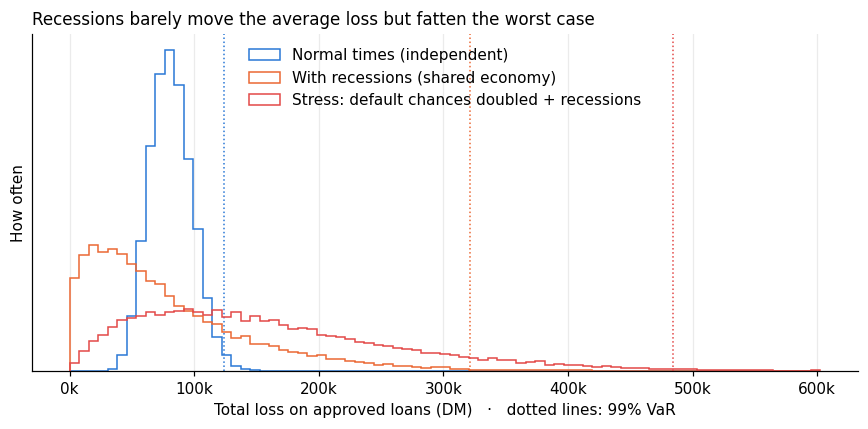

In [44]:
from scipy.stats import norm
sim_rng = np.random.default_rng(SEED)
N_SIM, RHO = 20_000, 0.2             # RHO: how strongly borrowers share the economy's luck

def simulate(approve, pd_scale=1.0, rho=0.0):
    pd_i = np.clip((1 - p_lr[approve]) * pd_scale, 0, 0.999)
    exposure = amt[approve]
    economy = sim_rng.standard_normal((N_SIM, 1))
    own = sim_rng.standard_normal((N_SIM, len(pd_i)))
    latent = np.sqrt(rho) * economy + np.sqrt(1 - rho) * own
    return (latent < norm.ppf(pd_i)) @ exposure

approve_orig = p_lr > THRESHOLD
def simulate_fresh(*args, **kwargs):
    """Same random futures every time (fixed seed), so numbers match between sections 7.2 and 7.3."""
    global sim_rng
    sim_rng = np.random.default_rng(SEED)
    return simulate(*args, **kwargs)
scenarios = {"Normal times (independent)": simulate_fresh(approve_orig),
             "With recessions (shared economy)": simulate_fresh(approve_orig, rho=RHO),
             "Stress: default chances doubled + recessions": simulate_fresh(approve_orig, pd_scale=2, rho=RHO)}
lent = amt[approve_orig].sum()
risk = pd.DataFrame({k: {"expected loss": v.mean(), "VaR 95%": np.percentile(v, 95), "VaR 99%": np.percentile(v, 99)}
                     for k, v in scenarios.items()}).T
risk["VaR 99% as % of money lent"] = risk["VaR 99%"] / lent
print(f"Approved {approve_orig.sum()} loans, {lent:,.0f} DM lent in total\n")
display(risk.style.format({"expected loss": "{:,.0f}", "VaR 95%": "{:,.0f}", "VaR 99%": "{:,.0f}", "VaR 99% as % of money lent": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, max(np.percentile(v, 99.9) for v in scenarios.values()), 80)
for (k, v), c in zip(scenarios.items(), [BLUE, ORANGE, "#e34948"]):
    ax.hist(v, bins=bins, histtype="step", lw=2, color=c, density=True, label=k)
    ax.axvline(np.percentile(v, 99), color=c, lw=1, ls=":")
ax.set_xlabel("Total loss on approved loans (DM)   ·   dotted lines: 99% VaR")
ax.set_yticks([]); ax.set_ylabel("How often")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_title("Recessions barely move the average loss but fatten the worst case", loc="left", fontsize=11)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### 7.3 Does fairer lending make the bank riskier in a recession?
The key fairness question for tail risk. We run the same recession simulation for the fair fixes. To compare like with like, every policy's default chances come from the **same** risk estimate (the original model).

In [45]:
fair_policies = {"Original model (5/6)": policies["Original model (5/6)"],
                 "Fair fix: separate threshold (ratio 0.8)": policies["Fair fix: separate threshold (ratio 0.8)"],
                 "Fair fix: age deleted + reweighing": policies["Fair fix: age deleted + reweighing"]}
rows = []
for name, a in fair_policies.items():
    sim_rng = np.random.default_rng(SEED)            # same random futures for every policy
    losses = simulate(a, rho=RHO)
    lent_a = amt[a].sum()
    young_share = amt[a & young].sum() / lent_a
    rows.append({"policy": name, "loans": int(a.sum()), "young borrowers": int((a & young).sum()),
                 "money lent (DM)": lent_a, "expected loss": losses.mean(), "VaR 99% (recessions)": np.percentile(losses, 99),
                 "VaR 99% as % lent": np.percentile(losses, 99) / lent_a, "share of lending to under-25s": young_share})
fair_risk = pd.DataFrame(rows).set_index("policy")
display(fair_risk.style.format({"money lent (DM)": "{:,.0f}", "expected loss": "{:,.0f}", "VaR 99% (recessions)": "{:,.0f}",
                                "VaR 99% as % lent": "{:.1%}", "share of lending to under-25s": "{:.1%}"}))
o, f = fair_risk.iloc[0], fair_risk.iloc[1]
print("Recession strength (RHO) is an assumption, so check how much it matters:")
for r_ in [0.05, 0.1, 0.2, 0.3]:
    vals = []
    for name, a in fair_policies.items():
        sim_rng = np.random.default_rng(SEED)
        vals.append(np.percentile(simulate(a, rho=r_), 99) / amt[a].sum())
    print(f"  RHO {r_:.2f}: worst-case loss original {vals[0]:.1%}, separate threshold {vals[1]:.1%}, reweighing {vals[2]:.1%}")
print(f"Separate threshold: {int(f['young borrowers'] - o['young borrowers'])} more young borrowers; "
      f"worst-case loss {o['VaR 99% as % lent']:.1%} -> {f['VaR 99% as % lent']:.1%} of money lent")
print(f"\n'Net cost unchanged' is not 'losses unchanged': the separate threshold lends {f['money lent (DM)'] - o['money lent (DM)']:,.0f} DM more, "
      f"and expected losses on defaults rise from {o['expected loss']:,.0f} to {f['expected loss']:,.0f} DM.")

,loans,young borrowers,money lent (DM),expected loss,VaR 99% (recessions),VaR 99% as % lent,share of lending to under-25s
policy,,,,,,,
Original model (5/6),351,28,"880,083","81,330","321,653",36.5%,6.8%
Fair fix: separate threshold (ratio 0.8),369,46,"916,043","88,558","340,935",37.2%,10.5%
Fair fix: age deleted + reweighing,348,33,"880,785","82,322","326,117",37.0%,8.0%


Recession strength (RHO) is an assumption, so check how much it matters:
  RHO 0.05: worst-case loss original 21.1%, separate threshold 21.8%, reweighing 21.2%
  RHO 0.10: worst-case loss original 26.9%, separate threshold 27.1%, reweighing 27.1%
  RHO 0.20: worst-case loss original 36.5%, separate threshold 37.2%, reweighing 37.0%
  RHO 0.30: worst-case loss original 46.0%, separate threshold 47.1%, reweighing 46.4%
Separate threshold: 18 more young borrowers; worst-case loss 36.5% -> 37.2% of money lent

'Net cost unchanged' is not 'losses unchanged': the separate threshold lends 35,960 DM more, and expected losses on defaults rise from 81,330 to 88,558 DM.


**Caveats:** the average loss is the same with or without recessions by construction (the shared economy changes how defaults cluster, not how likely each one is), so only the worst case is a finding. Default chances come from oversampled data (30% bad), so absolute losses are too high. The recession strength (`RHO = 0.2`) is an assumption, not something this dataset can measure. Try changing it and re-running.

## 8. Interactive demo
Enter an applicant's details. You'll see their approval chance, the main reasons, what changes if they were 35, and what the fairer model says.

*In Colab the controls are live. Below them, a real applicant from the data is shown as a worked example.*

In [46]:
from IPython.display import HTML
from html import escape
nice = lambda s: s.replace("_", " ")

def explain(applicant):
    df = pd.DataFrame([applicant])[COLS]
    p = p_good(df)[0]
    p35 = p_good(df.assign(age=35))[0]
    p_fair = fair_full.predict_proba(df.drop(columns="age"))[0, 1]
    z = prep.transform(df)[0]
    reasons = pd.Series(lr.coef_[0] * (z - Z.mean(0)), index=col_names)
    reasons = reasons.groupby([original_feature(n) for n in col_names]).sum().sort_values()
    def describe(f):
        return f"{nice(f)}: <b>{escape(show_value(f, applicant[f]))}</b>"
    age_rank = int(reasons.abs().rank(ascending=False)["age"])
    age_line = (f"<p style='color:#555;font-size:13px'>Age's own effect for this person: {reasons['age']:+.2f} on the score "
                f"({'helps' if reasons['age'] > 0 else 'hurts'}), the #{age_rank} biggest of {len(reasons)} details. "
                f"A small effect can still flip a decision when someone sits right on the line.</p>")
    against = "".join(f"<li>{describe(f)}</li>" for f in reasons.index[:3] if reasons[f] < 0)
    for_ = "".join(f"<li>{describe(f)}</li>" for f in reasons.index[::-1][:3] if reasons[f] > 0)
    verdict = lambda q: ("<span style='color:#008300'><b>LEND</b></span>" if q > THRESHOLD
                         else "<span style='color:#e34948'><b>DON'T LEND</b></span>")
    flip = ""
    if applicant["age"] < 25:
        flip = (f"<p><b>Flip test:</b> the same person aged 35 → {p35:.1%} ({verdict(p35)})"
                + (" &nbsp;⚠️ <b>decision changes with age alone</b>" if (p > THRESHOLD) != (p35 > THRESHOLD) else "") + "</p>")
    return HTML(f'''
    <div style="font-family:sans-serif;border:1px solid #ddd;border-radius:8px;padding:12px 16px;max-width:620px">
      <p style="font-size:18px;margin:0">Chance of being a good risk: <b>{p:.1%}</b> → {verdict(p)}
         <span style="color:#777;font-size:13px">(lends above {THRESHOLD:.1%})</span></p>
      <p style="margin:8px 0 2px"><b>Main reasons against:</b></p><ul style="margin:0">{against or "<li>none</li>"}</ul>
      <p style="margin:8px 0 2px"><b>Main reasons for:</b></p><ul style="margin:0">{for_ or "<li>none</li>"}</ul>
      {flip}
      {age_line}
      <p><b>Fairer model</b> (no age, reweighed): {p_fair:.1%} → {verdict(p_fair)}</p>
    </div>''')

# Worked example: a real under-25 applicant whose decision flips with age alone
ex = X.iloc[EX_IDX].to_dict()
print(f"Worked example: applicant #{EX_IDX}, age {ex['age']}, borrowing {ex['amount']:,} DM for {ex['duration']} months")
display(explain(ex))

Worked example: applicant #144, age 23, borrowing 2,288 DM for 21 months


In [47]:
# Live controls (work in Colab / Jupyter)
import ipywidgets as wdg
SLIDERS = {"age": (18, 75, 1), "duration": (4, 72, 1), "amount": (250, 18500, 250), "installment_rate": (1, 4, 1),
           "present_residence": (1, 4, 1), "number_credits": (1, 4, 1), "people_liable": (1, 2, 1)}
controls = {}
for c in COLS:
    if c in SLIDERS:
        lo, hi, step = SLIDERS[c]
        controls[c] = wdg.IntSlider(value=int(typical[c]) if c != "age" else 22, min=lo, max=hi, step=step,
                                    description=nice(c), style={"description_width": "150px"}, layout=wdg.Layout(width="420px"))
    else:
        controls[c] = wdg.Dropdown(options=sorted(X[c].unique()), value=typical[c], description=nice(c),
                                   style={"description_width": "150px"}, layout=wdg.Layout(width="420px"))
out = wdg.interactive_output(lambda **a: display(explain(a)), controls)
display(wdg.HBox([wdg.VBox(list(controls.values())), out]))

### 8.1 The full walkthrough page
A step-by-step explanation of the whole project for someone with no background: the bank's problem, the two lazy baselines, how much our model saves, how we tested it, the unfairness, the fix, and a live demo. Run the cell below; nothing needs installing.

In [48]:
#@title Show the interactive demo page { display-mode: "form" }
# The demo page is stored inside this cell so the notebook works on its own; it runs entirely in your browser.
import base64
from IPython.display import HTML, display
DEMO_PAGE = "..."
display(HTML('<iframe srcdoc="' + base64.b64decode(DEMO_PAGE).decode("utf-8").replace("&", "&amp;").replace('"', "&quot;") + '" style="width:100%;height:1400px;border:0;border-radius:12px;background:#000"></iframe>'))

## 9. Limitations, and how to overcome them

| Limitation | Why it matters | How to overcome it |
|---|---|---|
| **Small data:** 1,000 loans, 149 under 25 | Wide confidence intervals; results could shift with more data | Use a larger modern dataset (e.g. public US or Taiwan credit data) and repeat the audit |
| **Old data:** 1973–75, one German bank | Young people's finances and lending rules have changed | Re-run on recent data; compare with how UK lenders work today |
| **Oversampled bad loans** (30% bad vs a reported ~5% in reality) | Costs and default chances inflated; approval rates too low, and at a realistic rate the gap shrinks (section 2.6) | Reweight to a realistic default rate before setting cut-offs; validate on data with the real rate |
| **Only granted loans** | Rejected applicants are missing, so any past bias in who was approved is baked in | "Reject inference" methods, or data that includes rejected applicants |
| **Codebook errors** in the Statlog version | Wrong labels lead to wrong explanations | Fixed: corrected labels from South German Credit (section 1.1b) |
| **Ordered categories treated as numbers** (installment rate, years at address, credits, people supported) | The model assumes evenly spaced steps | Treat them as categories, or force a one-way (monotone) effect |
| **Broken sex variable** | We can't test sex or intersectional bias | Use datasets that record sex reliably; push data owners to document coding |
| **Fix cut-off chosen out of fold, not in a full inner loop** (section 5) | The other folds' predictions come from models that saw the test fold, so a little optimism could remain | Choose the cut-off with an inner cross-validation inside each training fold |
| **No dates on the loans** | We can't see how defaults move together in a downturn, so tail-risk numbers rely on an assumed `RHO` | Calibrate to historical default rates across economic cycles |
| **One definition of fairness** | Equal approval rates and equal chances for good risks can't always both hold | Report several measures (we show three) and explain the trade-off |
| **Thin information about ability to pay** | See 9.1 | Income, outgoings and credit bureau data |

### 9.1 Are we measuring creditworthiness?
**Question:** does this dataset contain what a lender would actually need to judge whether someone can repay?

| A real lender would want | In this dataset? |
|---|---|
| Income | **No.** Only the repayment as a share of income, in 4 bands |
| Existing debts and their size | Partly: number of credits at this bank (banded) and other instalment plans (bank, stores or none), but no amounts |
| Repayment history | Partly: a 5-level credit history category |
| Savings and cash | Partly: checking and savings balances, in bands |
| Assets | Partly: the most valuable type of property owned, but not its value |
| Job stability | Yes: years in current job, job type |
| Loan size compared with what they have | Only indirectly, through the repayment-to-income band |
| Credit bureau score, spending, rent payment record | No |

**What this means.** The model can't measure ability to pay directly, so it leans on stand-ins such as job length, family status and housing, which are exactly the details that differ by age (section 4.1). Someone with no borrowing history isn't necessarily risky, but a model with little else to go on can treat "unknown" as "risky". This is called the **thin file** problem.

Economists describe lending as a market with **information asymmetry**: the borrower knows more about their own situation than the bank does. A strict cut-off like our 83% is a form of **credit rationing**: instead of charging riskier-looking people more, the bank turns them away. Because it can't tell people apart well, reliable applicants who *look* risky get turned away too. Charging higher interest instead can backfire through **adverse selection**: careful borrowers drop out, and the riskier ones stay.

**What would need to change before this could be a real credit system:** income and outgoings (an affordability check), full credit bureau history, recent data from the people it would actually be used on, records of rejected applicants, monitoring of outcomes by age after launch, and a legal review of how age and its proxies are used.

In [49]:
acc50 = results.loc[BEST, "accuracy at 50% threshold"]
print("HEADLINE NUMBERS")
print(f"  Model: {BEST}, 5-fold cross-validated with nested tuning; cut-off 5/6 from the 5:1 cost rule")
print(f"  Ranking quality: ROC AUC {results.loc[BEST, 'AUC']:.3f}. Cost {results.loc[BEST, 'cost']:,.0f} at 5/6, "
      f"vs 700 reject-everyone and 1,500 approve-everyone")
print(f"  (Accuracy is {results.loc[BEST, 'accuracy']:.1%} at 5/6 and {acc50:.1%} at 50%; the bank optimises cost, not accuracy)")
print(f"  Approval: under 25 {gm.loc['Under 25', 'approval rate']:.1%}, 25+ {gm.loc['25 or older', 'approval rate']:.1%}, "
      f"gap {point['approval gap'] * 100:.1f} points (95% CI {ci['approval gap'][0] * 100:.0f} to {ci['approval gap'][1] * 100:.0f})")
print(f"  Among people who repaid: under 25 {gm.loc['Under 25', 'approval rate among good risks']:.1%}, "
      f"25+ {gm.loc['25 or older', 'approval rate among good risks']:.1%}, gap {point['good-risk approval gap'] * 100:.1f} points "
      f"(95% CI {ci['good-risk approval gap'][0] * 100:.1f} to {ci['good-risk approval gap'][1] * 100:.1f})")
print(f"  At a realistic 5% bad-loan rate: gap {pt_r['approval gap'] * 100:.1f} points "
      f"(95% CI {ci_r['approval gap'][0] * 100:.1f} to {ci_r['approval gap'][1] * 100:.1f})")
print(f"  Deleting age: gap {fixes.loc['Age deleted', 'gap (points)']:.1f} points (bias survives through proxies)")
best_fix = "Separate threshold: ratio 0.8, chosen out of fold"
bf = fixes.loc[[i for i in fixes.index if i.startswith(best_fix)][0]]
rw = fixes.loc["Age deleted + reweighing"]
print(f"  Age-blind fix (age deleted + reweighing): good-risk gap {rw['good-risk gap (points)']:.1f}, cost {rw['cost']:,.0f}")
print(f"  Age-based fix (separate cut-off, chosen out of fold): good-risk gap {bf['good-risk gap (points)']:.1f}, "
      f"cost {bf['cost']:,.0f} (original {base_cost:,.0f}); legality uncertain (section 5.1)")
print(f"  Flip test: {gained.sum()} of {young.sum()} under-25s would be approved if they were 35")

HEADLINE NUMBERS
  Model: Logistic regression, 5-fold cross-validated with nested tuning; cut-off 5/6 from the 5:1 cost rule
  Ranking quality: ROC AUC 0.787. Cost 547 at 5/6, vs 700 reject-everyone and 1,500 approve-everyone
  (Accuracy is 58.5% at 5/6 and 75.0% at 50%; the bank optimises cost, not accuracy)
  Approval: under 25 18.8%, 25+ 38.0%, gap 19.2 points (95% CI 12 to 26)
  Among people who repaid: under 25 28.4%, 25+ 47.9%, gap 19.5 points (95% CI 8.8 to 29.7)
  At a realistic 5% bad-loan rate: gap 7.9 points (95% CI 2.1 to 14.3)
  Deleting age: gap 17.9 points (bias survives through proxies)
  Age-blind fix (age deleted + reweighing): good-risk gap 12.8, cost 538
  Age-based fix (separate cut-off, chosen out of fold): good-risk gap 2.4, cost 547 (original 547); legality uncertain (section 5.1)
  Flip test: 2 of 149 under-25s would be approved if they were 35


## 10. Straight answers
The six questions the project set out to answer, with every number printed from the analysis above.

In [50]:
lr_top = perm_mean[BEST].sort_values(ascending=False)
gap_drivers = by_feature.sort_values(ascending=False)
d_rej = boot_cost_of(oof[BEST] > THRESHOLD) - boot_cost_of(np.zeros(len(y), bool))
cal_young = boot_mean(surprise, young)
print("1. WHICH MODEL SHOULD BE THE PRIMARY MODEL?")
print(f"   {BEST}. It isn't measurably more expensive than the others (section 1.5), it overfits least "
      f"({overfit[BEST]:.1%} training-vs-unseen drop vs {max(overfit.values()):.1%} for the worst), and every weight can be read and explained.")
print("\n2. WHICH VARIABLES DRIVE ITS PREDICTIONS?")
PLAIN = {"status": "checking account", "personal_status_sex": "family status", "duration": "loan length",
         "amount": "loan amount", "installment_rate": "installment rate band", "credit_history": "credit history"}
plain = lambda f: PLAIN.get(f, f.replace("_", " "))
print("   By permutation importance (fall in ROC AUC when shuffled): "
      + ", ".join(f"{plain(f)} ({v:.3f})" for f, v in lr_top.head(5).items()) + ".")
print("   The age GAP is driven mostly by: " + ", ".join(f"{plain(f)} ({v:+.2f})" for f, v in gap_drivers.head(3).items())
      + " (section 3, log-odds). These are predictive links, not proof of cause.")
print("\n3. HOW CONFIDENT SHOULD WE BE IN ITS PREDICTIONS?")
print(f"   Ranking: ROC AUC {results.loc[BEST, 'AUC']:.3f} (0.5 = coin flip). Saving vs reject-everyone: "
      f"{-np.percentile(d_rej, 97.5):.0f} to {-np.percentile(d_rej, 2.5):.0f} cost points (95% interval).")
print(f"   Probabilities: under-25s repaid {100 * cal_young[0]:+.1f} points vs predicted ({100 * cal_young[1]:+.1f} to {100 * cal_young[2]:+.1f}), "
      f"so no measurable bias in the scores themselves, but mistakes of up to about 10 points could hide in data this small.")
print(f"   The age gap among good risks: {point['good-risk approval gap'] * 100:.1f} points "
      f"({ci['good-risk approval gap'][0] * 100:.1f} to {ci['good-risk approval gap'][1] * 100:.1f}). Real in this sample, but wide.")
print("\n4. WHAT THRESHOLD SHOULD DECIDE APPROVAL?")
print(f"   5/6 ({THRESHOLD:.1%}), derived from the 5:1 cost rule before seeing results (section 1.2). It is only right if the probabilities "
      f"are calibrated (they are, within noise) and the 5:1 costs are real. At a realistic 5% bad-loan rate the same rule means a cut-off of "
      f"{T_REAL:.2f} on these scores (section 2.6).")
print("\n5. THE MOST IMPORTANT WEAKNESSES OF THE DATASET")
print("   Only 1,000 loans from 1973–75; bad loans oversampled (30% vs about 5%); rejected applicants missing; no income or debt amounts;")
print("   a broken sex variable; and a codebook with wrong labels (fixed here using South German Credit).")
print("\n6. WHAT WOULD NEED TO CHANGE BEFORE THIS COULD BE A REAL CREDIT SYSTEM?")
print("   Recent data from the people it would be used on, including rejected applicants; income, outgoings and credit bureau data;")
print("   probabilities re-calibrated to the real default rate; a legal review of age and its proxies (section 5.1);")
print("   and monitoring approval and default rates by age after launch.")

1. WHICH MODEL SHOULD BE THE PRIMARY MODEL?
   Logistic regression. It isn't measurably more expensive than the others (section 1.5), it overfits least (3.9% training-vs-unseen drop vs 20.4% for the worst), and every weight can be read and explained.

2. WHICH VARIABLES DRIVE ITS PREDICTIONS?
   By permutation importance (fall in ROC AUC when shuffled): checking account (0.089), purpose (0.021), credit history (0.021), loan length (0.021), installment rate band (0.017).
   The age GAP is driven mostly by: checking account (+0.22), age (+0.20), family status (+0.12) (section 3, log-odds). These are predictive links, not proof of cause.

3. HOW CONFIDENT SHOULD WE BE IN ITS PREDICTIONS?
   Ranking: ROC AUC 0.787 (0.5 = coin flip). Saving vs reject-everyone: 85 to 215 cost points (95% interval).
   Probabilities: under-25s repaid -2.3 points vs predicted (-9.7 to +4.9), so no measurable bias in the scores themselves, but mistakes of up to about 10 points could hide in data this small.
   

In [51]:
# ===== PRINT EVERY RESULT IN ONE GO =====
# Paste this as the LAST cell, after Runtime -> Run all. It only reads results that earlier cells
# already made (it trains nothing), skips anything missing, and also saves everything to a text file.
import io, os, sys, contextlib
import numpy as np
import pandas as pd


def print_all_results(save_to="LoanCheck_all_results.txt"):
    G = globals()
    missing = []          # names the report looked for and could not find

    # ---------- small helpers ----------
    def need(*names):
        gone = [n for n in names if n not in G]
        missing.extend(gone)
        return not gone

    def is_num(v):
        return isinstance(v, (int, float, np.integer, np.floating)) and not isinstance(v, (bool, np.bool_))

    def is_pair(v):
        try:
            return (isinstance(v, (tuple, list, np.ndarray)) and np.ndim(v) == 1
                    and len(v) == 2 and all(is_num(x) for x in v))
        except Exception:
            return False

    def fmt_value(v):
        if is_pair(v):                                   # confidence interval
            return f"{float(v[0]):.4f} to {float(v[1]):.4f}"
        if isinstance(v, (pd.DataFrame, pd.Series)):
            return "\n" + v.to_string()
        if isinstance(v, np.ndarray):
            return np.array2string(v, threshold=sys.maxsize, max_line_width=200)
        if isinstance(v, (int, np.integer)) and not isinstance(v, (bool, np.bool_)):
            return f"{int(v):,}"
        if is_num(v):
            return f"{float(v):.4f}"
        return str(v)

    def wordy(df):
        # True when a text column holds long sentences (they get printed one row at a time)
        for j in range(df.shape[1]):
            col = df.iloc[:, j]
            if pd.api.types.is_numeric_dtype(col):
                continue
            try:
                if col.astype(str).str.len().max() > 60:
                    return True
            except Exception:
                pass
        return False

    def render(obj, fmt=None):
        # a styled table: use the numbers underneath it
        if type(obj).__name__ == "Styler" and isinstance(getattr(obj, "data", None), pd.DataFrame):
            obj = obj.data
        if fmt is not None:
            try:
                print(fmt(obj))
                return
            except Exception:
                pass                                     # fall back to the plain printer below
        if isinstance(obj, pd.DataFrame):
            if wordy(obj):
                for idx, row in obj.iterrows():
                    print(f"  * {idx}")
                    for c, v in row.items():
                        print(f"      {c}: {v}")
            else:
                print(obj.to_string())
        elif isinstance(obj, pd.Series):
            print(obj.to_string())
        elif isinstance(obj, dict):
            for k, v in obj.items():
                print(f"  {k}: {fmt_value(v)}")
        elif isinstance(obj, (tuple, list, np.ndarray)) or is_num(obj):
            print(f"  {fmt_value(obj)}")
        else:
            print(f"  {obj}")

    def show(title, name, fmt=None):
        obj = G.get(name)
        if obj is None:
            missing.append(name)
            print(f"\n--- {title}: not found (run the earlier cells first)")
            return
        print(f"\n--- {title}")
        try:
            render(obj, fmt)
        except Exception as e:
            print(f"  (couldn't print {name}: {type(e).__name__}: {e})")

    def num_fmt(v):
        # plain numbers in the text file: no scientific notation for money, small values stay visible
        if v != v:
            return "NaN"
        a = abs(v)
        if np.isfinite(v) and a >= 1 and v == round(v):
            return f"{v:,.0f}"
        if a >= 1000:
            return f"{v:,.0f}"
        if a >= 100:
            return f"{v:.2f}"
        if a != 0 and a < 1e-4:
            return f"{v:.3e}"
        return f"{v:.4f}"

    def section(t):
        print("\n" + "=" * 100 + f"\n{t}\n" + "=" * 100)

    @contextlib.contextmanager
    def guard(label):
        # one broken line must never stop the rest of the report
        try:
            yield
        except Exception as e:
            print(f"  ({label}: couldn't print: {type(e).__name__}: {e})")

    # ---------- the report ----------
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf), pd.option_context(
            "display.width", 250, "display.max_columns", 50,
            "display.max_rows", 500, "display.max_colwidth", 120, "display.float_format", num_fmt):

        section("1. DATA AND MODELS")
        with guard("summary"):
            bits = []
            if "SOURCE" in G:
                bits.append(f"Source: {G['SOURCE']}")
            else:
                missing.append("SOURCE")
            if need("X"):
                bits.append(f"applicants: {len(G['X'])}")
            if need("young"):
                yg = np.asarray(G["young"]).astype(bool)
                bits += [f"under 25: {int(yg.sum())}", f"25+: {int((~yg).sum())}"]
            if bits:
                print("   ".join(bits))
        with guard("cut-off"):
            if need("THRESHOLD"):
                print(f"Cut-off (from the 5:1 cost rule): {float(G['THRESHOLD']):.4f}")
        show("1.1 First look: who actually repaid", "first_look")
        with guard("1.1b"):
            if isinstance(G.get("check_rows"), list):
                print("\n--- 1.1b Label check against South German Credit")
                print(pd.DataFrame(G["check_rows"]).to_string(index=False))
            else:
                missing.append("check_rows")
                print("\n--- 1.1b Label check against South German Credit: not found (run the earlier cells first)")
        show("1.2 Baselines", "baselines")
        show("1.4 Models: accuracy, cost, approvals", "results")
        show("1.4b Full scorecard at 5/6", "scorecard")
        show("1.4c Overfitting check (training vs unseen accuracy)", "fit_check")
        with guard("1.5 model choice"):
            print(f"\n--- 1.5 Model choice\n  Cheapest: {G.get('cheapest')}   "
                  f"In the running: {G.get('in_running')}   CHOSEN: {G.get('BEST')}")
            for n in ("cheapest", "in_running", "BEST"):
                if n not in G:
                    missing.append(n)
            if need("d_rej"):
                print(f"  Saving vs reject-everyone, 95% interval: "
                      f"{-np.percentile(G['d_rej'], 97.5):.0f} to {-np.percentile(G['d_rej'], 2.5):.0f} cost points")
        show("1.5 Three models side by side", "comparison")

        section("2. FAIRNESS")
        show("2.1 Approval by age group (chosen model, 5/6)", "gm")
        show("2.1 Gaps (point estimates)", "point")
        show("2.1 Gaps (95% confidence intervals)", "ci")
        with guard("2.2 real gap"):
            if need("real_gap"):
                print(f"\n--- 2.2 Real difference in repayment rate (25+ minus under 25): "
                      f"{float(G['real_gap']) * 100:+.1f} points")
        show("2.2 Fairness of each model", "compare")
        show("2.4 Every age cut-off from 22 to 35", "cuts")
        show("2.4 Age bands with counts", "age_bands")
        with guard("2.6 realistic cut-off"):
            if need("T_REAL"):
                print(f"\n--- 2.6 Realistic 5% bad-loan bank: equivalent cut-off {float(G['T_REAL']):.4f}")
            else:
                print("\n--- 2.6 Realistic 5% bad-loan bank: equivalent cut-off not found (run the earlier cells first)")
        show("2.6 Approval by group at the realistic rate", "gm_r")
        show("2.6 Gaps at the realistic rate", "pt_r")
        show("2.6 95% intervals at the realistic rate", "ci_r")

        section("3. WHAT DRIVES THE GAP, AND WHAT EACH MODEL RELIES ON")
        show("3. Contribution of each detail to the age score gap (log-odds)",
             "by_feature", fmt=lambda s: s.sort_values(ascending=False).round(4).to_string())
        show("3.2 Logistic regression: 15 strongest terms (odds ratios)", "top_terms")
        show("3.2 Logistic regression: spread of contribution per detail", "lr_weight")
        show("3.2 Permutation importance, all three models", "imp_table")
        show("3.3 Hypothetical applicant (age 30) step by step", "walk")
        with guard("3.3 final chance"):
            if need("total", "sigmoid"):
                print(f"  Final chance of repaying: {float(G['sigmoid'](G['total'])):.4f} -> {G.get('verdict_txt')}")

        section("4. PROXIES")
        with guard("4 all details together"):
            if need("p_young", "y_young", "roc_auc_score"):
                print(f"All details together (age hidden) predict 'under 25' with AUC "
                      f"{G['roc_auc_score'](G['y_young'], G['p_young']):.4f}")
        show("4.1 Each detail on its own: AUC for guessing 'under 25' (0.5 = guessing)",
             "proxy_auc", fmt=lambda s: s.sort_values(ascending=False).to_string())
        with guard("4 top proxies"):
            if need("TOP_PROXIES"):
                print(f"  Top 3 proxies: {G['TOP_PROXIES']}")

        section("5. FIXES AND THEIR COST")
        show("5. Every fix compared", "fixes")
        with guard("5 out-of-fold cut-offs"):
            if need("T_OOF"):
                print(f"  Under-25 cut-offs chosen out of fold: {G['T_OOF']}")
        with guard("5 cost difference"):
            if need("diff"):
                lo_, hi_ = np.percentile(G["diff"], [2.5, 97.5])
                print(f"  Cost difference (out-of-fold fix minus original), 95% interval: {lo_:+.0f} to {hi_:+.0f}")
        show("5. Approval by group after the out-of-fold fix", "gm_f")
        show("5. Gaps after the fix", "pt_f")
        show("5. 95% intervals after the fix", "ci_f")

        section("6. FLIP TEST, DATA AUDIT, DEEPER CHECKS")
        with guard("6.1 flip test"):
            if need("gained", "lost", "young"):
                yg = np.asarray(G["young"]).astype(bool)
                print(f"Under-25s rejected now but approved at 35: {int(np.sum(G['gained']))} of {int(yg.sum())}")
                print(f"25+ approved now but rejected at 22: {int(np.sum(G['lost']))} of {int((~yg).sum())}")
        show("6.2 Data audit", "audit")
        show("6.3.1 Calibration by age group", "calibration")
        show("6.3.2 Like-for-like gap (similar finances)", "lfl")
        show("6.3.3 Good risks by age band, before and after the fix", "bands_table")
        show("6.3.3 Original vs fix vs age-blind lower cut-off", "cliff")

        section("7. TAIL RISK")
        show("7.1 Cost in money (DM)", "money")
        show("7.2 Losses in normal times, recessions and stress", "risk")
        show("7.3 Tail risk of each fix", "fair_risk")

        print("\n" + "=" * 100)
        if missing:
            print("Not found (skipped): " + ", ".join(sorted(set(missing))))
        else:
            print("Every expected result was found.")
    text = buf.getvalue()
    print(text)
    if save_to:
        try:
            with open(save_to, "w", encoding="utf-8") as fh:
                fh.write(text)
            print(f"\nSaved to {os.path.abspath(save_to)} (Colab: folder icon on the left to download it).")
        except Exception as e:
            print(f"\nCould not save {save_to}: {type(e).__name__}: {e}")


print_all_results()



1. DATA AND MODELS
Source: UCI, fetch_ucirepo(id=144)   applicants: 1000   under 25: 149   25+: 851
Cut-off (from the 5:1 cost rule): 0.8333

--- 1.1 First look: who actually repaid
             applicants  repaid (good)  did not repay (bad)  actually good risk
Under 25            149             88                   61              0.5906
25 or older         851            612                  239              0.7192

--- 1.1b Label check against South German Credit
             detail                              label we use                          corrected codebook rows that agree
             status                                  0-200 DM                                    0-200 DM        62 of 62
             status                        < 0 DM (overdrawn)                                      < 0 DM      266 of 266
             status               >= 200 DM or salary account      >= 200 DM / salary for at least 1 year      389 of 389
             status                    

In [52]:
from google.colab import files
files.download('/content/LoanCheck_all_results.txt')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>